Step 1 — Check the GPU and workspace

In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
assert Path("/workspace").is_dir(), "/workspace is missing."

for name in ("configs", "logs", "results", "notebooks"):
    (ROOT / name).mkdir(parents=True, exist_ok=True)

checks = [
    ["nvidia-smi"],
    ["free", "-h"],
    ["df", "-h", "/workspace"],
    ["findmnt", "-T", "/workspace"],
]

report = [f"Notebook Python: {sys.version}\n"]

for command in checks:
    result = subprocess.run(
        command, capture_output=True, text=True, check=True
    )
    print(result.stdout, flush=True)
    report.append(result.stdout)

(ROOT / "logs/step1_hardware.log").write_text("\n".join(report))

print("Experiment folder:", ROOT)
print("STEP 1 COMPLETE")

Sun Nov 15 20:04:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.91.07              Driver Version: 595.91.07      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX A6000               On  |   00000000:D6:00.0 Off |                    0 |
| 30%   41C    P8             33W /  300W |       0MiB /  46068MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Step 2 — Clone the original repository

In [2]:
from pathlib import Path
import subprocess
import json

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
REPO = ROOT / "repo"
COMMIT = "ad2f69295797a5f03e7b480246080d91087d9007"
URL = "https://github.com/timothee-chauvin/token-efficient-change-detection-llm-apis"

def run(command):
    result = subprocess.run(
        command, check=True, capture_output=True, text=True
    )
    return result.stdout.strip()

if not REPO.exists():
    print("Cloning repository...", flush=True)
    run(["git", "clone", URL, str(REPO)])

assert (REPO / ".git").is_dir(), f"Invalid repository folder: {REPO}"

current = run(["git", "-C", str(REPO), "rev-parse", "HEAD"])
if current != COMMIT:
    changes = run(["git", "-C", str(REPO), "status", "--porcelain"])
    assert not changes, "Repository has local edits. Send this output."
    run(["git", "-C", str(REPO), "checkout", "--detach", COMMIT])

verified = run(["git", "-C", str(REPO), "rev-parse", "HEAD"])
assert verified == COMMIT
assert (REPO / "track-llm-apis/pyproject.toml").is_file()

settings = {
    "project_root": str(ROOT),
    "repository": str(REPO),
    "repository_url": URL,
    "commit": verified,
}
(ROOT / "configs/repository.json").write_text(
    json.dumps(settings, indent=2)
)

print("Repository:", REPO)
print("Verified commit:", verified)
print("STEP 2 COMPLETE")

Cloning repository...
Repository: /workspace/B3IT_Token_Edits_Fresh/repo
Verified commit: ad2f69295797a5f03e7b480246080d91087d9007
STEP 2 COMPLETE


Step 3 — Create a fresh Python environment

In [3]:
from pathlib import Path
import os
import subprocess
import sys
import json

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
TOOLS = ROOT / "tools"
TOOLS.mkdir(exist_ok=True)

env = os.environ.copy()
env["UV_PYTHON_INSTALL_DIR"] = str(TOOLS / "python")
env["UV_CACHE_DIR"] = str(TOOLS / "uv_cache")
env["PYTHONPATH"] = str(TOOLS / "uv_package")

log_path = ROOT / "logs/step3_environment.log"

commands = [
    [
        sys.executable, "-m", "pip", "install",
        "--target", str(TOOLS / "uv_package"), "uv==0.13.8",
    ],
    [
        sys.executable, "-m", "uv", "python", "install", "3.11.18",
    ],
    [
        sys.executable, "-m", "uv", "venv",
        "--python", "3.11.18", str(ROOT / ".venv"),
    ],
]

with log_path.open("w") as log:
    for command in commands:
        with subprocess.Popen(
            command, env=env, stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
            if process.wait():
                raise RuntimeError(f"Environment setup failed. See {log_path}")

python = ROOT / ".venv/bin/python"
version = subprocess.check_output(
    [str(python), "--version"], text=True
).strip()

settings = {
    "python": str(python),
    "uv_python": sys.executable,
    "uv_package": str(TOOLS / "uv_package"),
    "python_install_dir": env["UV_PYTHON_INSTALL_DIR"],
    "uv_cache_dir": env["UV_CACHE_DIR"],
}
(ROOT / "configs/environment.json").write_text(
    json.dumps(settings, indent=2)
)

print("\nPython:", version)
print("Environment:", ROOT / ".venv")
print("STEP 3 COMPLETE")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/17.4 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 105.1 MB/s  0:00:00
Installed Python 3.11.18 in 20.09s
 + cpython-3.11.18-linux-x86_64-gnu (python3.11)
Using CPython 3.11.18
Creating virtual environment at: B3IT_Token_Edits_Fresh/.venv
Activate with: source B3IT_Token_Edits_Fresh/.venv/bin/activate

Python: Python 3.11.18
Environment: /workspace/B3IT_Token_Edits_Fresh/.venv
STEP 3 COMPLETE


Step 4 — Install dependencies and verify BF16

In [4]:
from pathlib import Path
import os
import subprocess
import json
import sys

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
PYTHON = ROOT / ".venv/bin/python"
PACKAGE = ROOT / "repo/track-llm-apis"
settings = json.loads((ROOT / "configs/environment.json").read_text())

env = os.environ.copy()
env["PYTHONPATH"] = settings["uv_package"]
env["UV_CACHE_DIR"] = settings["uv_cache_dir"]
env["UV_PYTHON_INSTALL_DIR"] = settings["python_install_dir"]
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"

log_path = ROOT / "logs/step4_install.log"

command = [
    sys.executable, "-m", "uv", "pip", "install",
    "--python", str(PYTHON),
    "-e", str(PACKAGE),
    "torch==2.9.1",
    "transformers==4.57.6",
    "vllm==0.15.0",
    "lightning==2.6.1",
    "nvidia-modelopt[hf]==0.41.0",
    "peft==0.18.1",
    "matplotlib",
    "scikit-learn",
]

print("Installing dependencies. Log:", log_path, flush=True)
with log_path.open("w") as log:
    with subprocess.Popen(
        command, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"Installation failed. Send the final output from {log_path}")

check = """
import importlib.metadata as metadata
import torch
import transformers
import vllm
import lightning
import peft
import track_llm_apis

for name in (
    "torch", "transformers", "vllm", "lightning",
    "nvidia-modelopt", "peft", "track-llm-apis"
):
    print(f"{name}: {metadata.version(name)}")

assert torch.cuda.is_available(), "CUDA unavailable"
assert torch.cuda.is_bf16_supported(), "BF16 unavailable"
x = torch.ones((32, 32), device="cuda", dtype=torch.bfloat16)
y = x @ x
torch.cuda.synchronize()
assert y[0, 0].item() == 32.0
print("GPU:", torch.cuda.get_device_name(0))
print("BF16 calculation passed")
"""

result = subprocess.run(
    [str(PYTHON), "-c", check],
    env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step4_verification.log").write_text(output)

if result.returncode:
    raise RuntimeError("Verification failed. Send the output above.")

frozen = subprocess.check_output(
    [
        sys.executable, "-m", "uv", "pip", "freeze",
        "--python", str(PYTHON)
    ],
    env=env, text=True
)
(ROOT / "configs/installed_packages.txt").write_text(frozen)
print("STEP 4 COMPLETE")

Installing dependencies. Log: /workspace/B3IT_Token_Edits_Fresh/logs/step4_install.log
Using Python 3.11.18 environment at: B3IT_Token_Edits_Fresh/.venv
Resolved 230 packages in 8.05s
Prepared 230 packages in 1m 11s
Installed 230 packages in 19.85s
 + accelerate==1.15.0
 + agent-detector==2.0.0
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + annotated-doc==0.0.6
 + annotated-types==0.8.0
 + anthropic==2.8.0
 + anyio==4.16.0
 + apache-tvm-ffi==0.1.16
 + astor==0.8.1
 + attrs==26.1.0
 + beartype==0.23.1
 + blake3==1.0.11
 + cachetools==8.0.0
 + cbor2==6.3.0
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + choreographer==1.4.0
 + click==8.5.1
 + cloudpickle==3.1.2
 + compressed-tensors==0.13.0
 + contourpy==1.3.3
 + cryptography==50.0.2
 + cuda-bindings==13.5.0
 + cuda-pathfinder==1.9.0
 + cupy-cuda12x==14.2.0
 + cycler==0.12.1
 + datasets==5.0.1
 + deepspeed==0.20.0
 + depyf==0.20.0
 + detect-installer==0.2.1
 + diffusers==0.39.0
 + dill==0.4.1
 

Using Python 3.11.18 environment at: B3IT_Token_Edits_Fresh/.venv


STEP 4 COMPLETE


Step 5 — Check replacement tokens

In [6]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")

code = r'''
import json
from pathlib import Path
from transformers import AutoTokenizer

root = Path("/workspace/B3IT_Token_Edits_Fresh")
model = "Qwen/Qwen2.5-0.5B-Instruct"
revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model, revision=revision)

baseline = (
     "You are a helpful assistant."
)

def encode_prompt(system):
    return tokenizer.apply_chat_template(
        [
            {"role": "system", "content": system},
            {"role": "user", "content": "Hello"},
        ],
        tokenize=True,
        add_generation_prompt=True,
    )

baseline_ids = encode_prompt(baseline)
variants = []

print("BASELINE:", baseline)
print("Chat-formatted baseline length:", len(baseline_ids))
print()

for label, word in zip("ABCD", ("polite", "respectful", "careful", "safe")):
    prompt = baseline.replace("a helpful assistant", f"a {word} assistant")
    ids = encode_prompt(prompt)
    same_length = len(ids) == len(baseline_ids)
    positions = (
        [i for i, (a, b) in enumerate(zip(baseline_ids, ids)) if a != b]
        if same_length else []
    )
    eligible = same_length and len(positions) == 1

    print(
        f"{label}: helpful → {word} | "
        f"length {len(ids)} | "
        f"one-token replacement: {eligible}"
    )

    variants.append({
        "label": label,
        "replacement_word": word,
        "system_prompt": prompt,
        "token_ids": ids,
        "same_length": same_length,
        "changed_positions": positions,
        "eligible": eligible,
    })

record = {
    "model": model,
    "model_revision": revision,
    "baseline_system_prompt": baseline,
    "baseline_token_ids": baseline_ids,
    "verification_user_message": "Hello",
    "variants": variants,
}

path = root / "configs/tokenizer_check.json"
path.write_text(json.dumps(record, indent=2))
print("\nSaved:", path)
print("STEP 5 COMPLETE")
'''

result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), "-c", code],
    env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step5_tokenizer.log").write_text(output)

if result.returncode:
    raise RuntimeError("Tokenizer check failed. Send the output above.")

BASELINE: You are a helpful assistant.
Chat-formatted baseline length: 20

A: helpful → polite | length 20 | one-token replacement: True
B: helpful → respectful | length 20 | one-token replacement: True
C: helpful → careful | length 20 | one-token replacement: True
D: helpful → safe | length 20 | one-token replacement: True

Saved: /workspace/B3IT_Token_Edits_Fresh/configs/tokenizer_check.json
STEP 5 COMPLETE



Step 6 — Save variants and load the repository’s sampling settings

In [7]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"

code = r'''
import json
from pathlib import Path
from track_llm_apis.config import config

root = Path("/workspace/B3IT_Token_Edits_Fresh")
checked = json.loads((root / "configs/tokenizer_check.json").read_text())

assert checked["baseline_system_prompt"] == "You are a helpful assistant."
assert len(checked["variants"]) == 4
assert all(v["eligible"] for v in checked["variants"])

config.data_dir = root / "data"
bi_settings = config.sampling.bi.model_dump(mode="json")

plan = {
    "model": checked["model"],
    "model_revision": checked["model_revision"],
    "baseline_system_prompt": checked["baseline_system_prompt"],
    "variants": checked["variants"],
    "dtype": "bfloat16",
    "repository_bi_settings": bi_settings,
    "adaptation": "Apply chat formatting and replace one system-prompt token.",
}

path = root / "configs/experiment.json"
if path.exists():
    assert json.loads(path.read_text()) == plan, "Existing experiment settings differ."

temp = path.with_suffix(".tmp")
temp.write_text(json.dumps(plan, indent=2))
temp.replace(path)

print("Baseline:", plan["baseline_system_prompt"])
for variant in plan["variants"]:
    print(f'{variant["label"]}: {variant["system_prompt"]}')

print("\nRepository BI settings:")
print(json.dumps(bi_settings, indent=2))
print("\nSaved:", path)
print("STEP 6 COMPLETE")
'''

result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), "-c", code],
    cwd=ROOT, env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step6_config.log").write_text(output)

if result.returncode:
    raise RuntimeError("Configuration failed. Send the output above.")

Baseline: You are a helpful assistant.
A: You are a polite assistant.
B: You are a respectful assistant.
C: You are a careful assistant.
D: You are a safe assistant.

Repository BI settings:
{
  "temperature": 0.0,
  "per_batch_input_fraction": 0.95,
  "batch_size": 64,
  "phase_1_queries_per_token": 3,
  "phase_1_tokens_per_endpoint": 20000,
  "phase_1_target_border_inputs": 20000,
  "phase_1_queries_per_bi": 1000,
  "phase_1b_min_bis": 10,
  "max_border_inputs": 120,
  "n_prompts": 10,
  "reference_samples_per_prompt": 50,
  "detection_samples_per_prompt": 10,
  "models": {
    "Qwen/Qwen2.5-0.5B-Instruct": 1,
    "Qwen/Qwen2.5-7B-Instruct": 1,
    "google/gemma-3-1b-it": 1,
    "google/gemma-2-9b-it": 1,
    "microsoft/Phi-4-mini-instruct": 1,
    "mistralai/Mistral-7B-Instruct-v0.3": 1,
    "deepseek-ai/DeepSeek-R1-Distill-Qwen-7B": 1,
    "meta-llama/Llama-3.1-8B-Instruct": 1,
    "allenai/OLMo-2-1124-7B-Instruct": 2
  }
}

Saved: /workspace/B3IT_Token_Edits_Fresh/configs/experime

Step 7 — Prepare background traffic

In [8]:
from pathlib import Path
from getpass import getpass
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")
env["HF_TOKEN"] = getpass("Hugging Face read token (hidden): ").strip()

code = r'''
from pathlib import Path
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts

root = Path("/workspace/B3IT_Token_Edits_Fresh")
config.data_dir = root / "data"

traffic = _load_traffic_prompts()
assert traffic, "Background traffic is empty."

print("Background requests:", len(traffic))
print("Processed dataset directory:", config.datasets_dir)
print("STEP 7 COMPLETE", flush=True)
'''

log_path = ROOT / "logs/step7_traffic.log"
print("Preparing LMSYS background traffic...", flush=True)

try:
    with log_path.open("w") as log:
        with subprocess.Popen(
            [str(ROOT / ".venv/bin/python"), "-c", code],
            cwd=ROOT, env=env, stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()

            if process.wait():
                raise RuntimeError(f"Traffic preparation failed. See {log_path}")
finally:
    env.pop("HF_TOKEN", None)

Hugging Face read token (hidden):  ········


Preparing LMSYS background traffic...
2026-11-15 20:24:45,822 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-15 20:24:45,823 - track-llm-apis - INFO - No processed dataset found at /workspace/B3IT_Token_Edits_Fresh/data/datasets/lmsys2flmsys-chat-1m, creating...

Generating train split: 100%|██████████| 1000000/1000000 [00:19<00:00, 50018.76 examples/s]
2026-11-15 20:25:26,023 - track-llm-apis - INFO - Filtering dataset...

Filter: 100%|██████████| 1000000/1000000 [00:00<00:00, 1080006.34 examples/s]

Map: 100%|██████████| 4570/4570 [00:08<00:00, 570.75 examples/s]

Filter: 100%|██████████| 4570/4570 [00:00<00:00, 12792.27 examples/s]

Saving the dataset (1/1 shards): 100%|██████████| 4502/4502 [00:00<00:00, 101997.83 examples/s]
2026-11-15 20:25:36,472 - track-llm-apis - INFO - Loaded 4502 traffic prompts
Background requests: 4502
Processed dataset directory: /workspace/B3IT_Token_Edits_Fresh/data/datasets
STEP 7 COMPLETE


Step 8 — Add system-prompt support to the repository

In [9]:
from pathlib import Path
import ast

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
source = (
    ROOT / "repo/track-llm-apis/src/track_llm_apis"
    / "sampling/vllm_sampling.py"
)
original = source.read_text()

old_signature = """    max_tokens: int,
) -> BIInferenceResult:"""

new_signature = """    max_tokens: int,
    system_prompt: str | None = None,
) -> BIInferenceResult:"""

old_generation = """            outputs = llm.generate(shuffled_batch, sampling_params, use_tqdm=False)"""

new_generation = """            # Apply the endpoint's system message to probes and traffic alike.
            generation_prompts = shuffled_batch
            if system_prompt is not None:
                generation_prompts = [
                    {
                        "prompt_token_ids": tokenizer.apply_chat_template(
                            [
                                {"role": "system", "content": system_prompt},
                                {"role": "user", "content": text},
                            ],
                            tokenize=True,
                            add_generation_prompt=True,
                        )
                    }
                    for text in shuffled_batch
                ]

            outputs = llm.generate(generation_prompts, sampling_params, use_tqdm=False)"""

if new_signature in original and new_generation in original:
    print("System-prompt support already installed.")
else:
    assert original.count(old_signature) == 1, "Unexpected function signature."
    assert original.count(old_generation) == 1, "Unexpected generation code."

    updated = original.replace(old_signature, new_signature)
    updated = updated.replace(old_generation, new_generation)
    ast.parse(updated)

    backup = ROOT / "backups/vllm_sampling.original.py"
    backup.parent.mkdir(exist_ok=True)
    if not backup.exists():
        backup.write_text(original)

    source.write_text(updated)

ast.parse(source.read_text())
print("Updated:", source)
print("Syntax check passed.")
print("STEP 8 COMPLETE")

Updated: /workspace/B3IT_Token_Edits_Fresh/repo/track-llm-apis/src/track_llm_apis/sampling/vllm_sampling.py
Syntax check passed.
STEP 8 COMPLETE


Step 9 — Discover fresh border inputs

In [10]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/discover.py"
script.parent.mkdir(exist_ok=True)

script.write_text(r'''
import json
import random
import time
from pathlib import Path

from transformers import AutoTokenizer
from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import (
    BIPhase1aOutput,
    BIPhase1ModelResult,
    get_single_token_inputs,
    _load_traffic_prompts,
)
from track_llm_apis.sampling.vllm_sampling import (
    vllm_inference_bi,
    cleanup_vllm,
)


def main():
    root = Path(__file__).resolve().parents[1]
    plan = json.loads((root / "configs/experiment.json").read_text())
    config.data_dir = root / "data"
    bi = config.sampling.bi
    assert bi.model_dump(mode="json") == plan["repository_bi_settings"]

    marker = root / "results/discovery_complete.json"
    if marker.exists():
        record = BIPhase1aOutput.load_model(
            plan["model"], temperature=bi.temperature
        )
        print("Using completed discovery from this experiment.")
        print("Candidates screened:", len(record.results))
        print("Border inputs found:", len(record.get_border_inputs()))
        print("STEP 9 COMPLETE", flush=True)
        return

    tokenizer = AutoTokenizer.from_pretrained(
        plan["model"], revision=plan["model_revision"]
    )
    candidates = get_single_token_inputs(
        tokenizer, bi.phase_1_tokens_per_endpoint
    )
    assert len(candidates) == 20_000
    traffic = _load_traffic_prompts()

    print(
        f"Screening {len(candidates)} candidates × "
        f"{bi.phase_1_queries_per_token} observations.",
        flush=True,
    )

    llm = LLM(
        model=plan["model"],
        revision=plan["model_revision"],
        tokenizer_revision=plan["model_revision"],
        dtype=plan["dtype"],
        enforce_eager=True,
        enable_prefix_caching=False,
        gpu_memory_utilization=0.80,
        seed=0,
    )

    random.seed(0)
    started = time.monotonic()
    result = vllm_inference_bi(
        llm=llm,
        inputs=candidates,
        traffic_prompts=traffic,
        n_samples=bi.phase_1_queries_per_token,
        temperature=bi.temperature,
        input_fraction=bi.per_batch_input_fraction,
        batch_size=bi.batch_size,
        max_tokens=bi.models[plan["model"]],
        system_prompt=plan["baseline_system_prompt"],
    )

    assert set(result.counts) == set(candidates)
    assert all(
        sum(counts.values()) == bi.phase_1_queries_per_token
        for counts in result.counts.values()
    )

    record = BIPhase1ModelResult(
        model_name=plan["model"],
        bi_config=bi.model_dump(mode="json"),
        phase="1a",
        results=result.counts,
        prompt_lengths=result.prompt_lengths,
        generation_time=time.monotonic() - started,
    )
    record.save()

    borders = record.get_border_inputs()
    details = {
        "model": plan["model"],
        "baseline_system_prompt": plan["baseline_system_prompt"],
        "candidates_screened": len(candidates),
        "border_inputs_found": len(borders),
        "generation_seconds": record.generation_time,
    }
    temp = marker.with_suffix(".tmp")
    temp.write_text(json.dumps(details, indent=2))
    temp.replace(marker)

    print("Candidates screened:", len(candidates), flush=True)
    print("Border inputs found:", len(borders), flush=True)
    print("Saved under:", config.bi_phase_1_dir, flush=True)
    cleanup_vllm(llm)
    print("STEP 9 COMPLETE", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step9_discovery.log"
print("Discovery log:", log_path, flush=True)

with log_path.open("a") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"Discovery stopped. Send the final output from {log_path}")

Discovery log: /workspace/B3IT_Token_Edits_Fresh/logs/step9_discovery.log
[2026-11-15 20:34:02] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-15 20:34:02] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Token_Edits_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-15 20:34:02] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
Screening 20000 candidates × 3 observations.
INFO 11-15 20:34:03 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-15 20:35:13 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-15 20:35:13 [model.py:1561] Using max model len 32768
INFO 11-15 20:35:18 [scheduler.py:226] Chunked prefill is enabled with max_num_batch

Step 10 — Calibrate the 416 border inputs

In [11]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/calibrate.py"

# Reuse the imports from the saved discovery runner.
imports = (ROOT / "scripts/discover.py").read_text().split("def main():")[0]

script.write_text(imports + r'''
def main():
    root = Path(__file__).resolve().parents[1]
    plan = json.loads((root / "configs/experiment.json").read_text())
    config.data_dir = root / "data"
    bi = config.sampling.bi
    assert bi.model_dump(mode="json") == plan["repository_bi_settings"]

    discovery = BIPhase1aOutput.load_model(
        plan["model"], temperature=bi.temperature
    )
    inputs = discovery.get_border_inputs()
    assert len(inputs) >= bi.phase_1b_min_bis
    rounds = bi.phase_1_queries_per_bi
    out = root / "results/calibration_blocks"
    out.mkdir(parents=True, exist_ok=True)

    settings = {
        "model": plan["model"],
        "revision": plan["model_revision"],
        "baseline": plan["baseline_system_prompt"],
        "inputs": inputs,
        "rounds": rounds,
        "block_size": 50,
        "seed_base": 10000,
        "bi_settings": bi.model_dump(mode="json"),
        "dtype": plan["dtype"],
    }
    manifest = out / "settings.json"
    if manifest.exists():
        assert json.loads(manifest.read_text()) == settings
    else:
        manifest.write_text(json.dumps(settings, indent=2))

    traffic = _load_traffic_prompts()
    llm = None
    counts = {p: {} for p in inputs}
    lengths = {}
    total_seconds = 0.0

    print(f"Calibrating {len(inputs)} inputs × {rounds} observations.", flush=True)

    for start in range(0, rounds, 50):
        path = out / f"block_{start:04d}.json"
        n = min(50, rounds - start)

        if path.exists():
            block = json.loads(path.read_text())
        else:
            if llm is None:
                llm = LLM(
                    model=plan["model"],
                    revision=plan["model_revision"],
                    tokenizer_revision=plan["model_revision"],
                    dtype=plan["dtype"],
                    enforce_eager=True,
                    enable_prefix_caching=False,
                    gpu_memory_utilization=0.80,
                    seed=0,
                )

            random.seed(settings["seed_base"] + start)
            started = time.monotonic()
            result = vllm_inference_bi(
                llm=llm,
                inputs=inputs,
                traffic_prompts=traffic,
                n_samples=n,
                temperature=bi.temperature,
                input_fraction=bi.per_batch_input_fraction,
                batch_size=bi.batch_size,
                max_tokens=bi.models[plan["model"]],
                system_prompt=plan["baseline_system_prompt"],
            )
            block = {
                "counts": result.counts,
                "prompt_lengths": result.prompt_lengths,
                "seconds": time.monotonic() - started,
            }
            temp = path.with_suffix(".tmp")
            temp.write_text(json.dumps(block))
            temp.replace(path)

        assert set(block["counts"]) == set(inputs)
        for prompt, token_counts in block["counts"].items():
            assert sum(token_counts.values()) == n
            for token, count in token_counts.items():
                counts[prompt][token] = counts[prompt].get(token, 0) + count

        lengths.update(block["prompt_lengths"])
        total_seconds += block["seconds"]
        print(f"Calibrated {start + n}/{rounds} rounds saved", flush=True)

    assert all(sum(c.values()) == rounds for c in counts.values())
    record = BIPhase1ModelResult(
        model_name=plan["model"],
        bi_config=bi.model_dump(mode="json"),
        phase="1b",
        results=counts,
        prompt_lengths=lengths,
        generation_time=total_seconds,
    )
    record.save()
    print(
        f"Varied again: {len(record.get_border_inputs())}/{len(inputs)}",
        flush=True,
    )

    if llm is not None:
        cleanup_vllm(llm)
    print("STEP 10 COMPLETE", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step10_calibration.log"
print("Calibration log:", log_path, flush=True)

with log_path.open("a") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"Calibration stopped. Send the final output from {log_path}")

Calibration log: /workspace/B3IT_Token_Edits_Fresh/logs/step10_calibration.log
[2026-11-15 20:49:55] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-15 20:49:55] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Token_Edits_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-15 20:49:55] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
Calibrating 416 inputs × 1000 observations.
INFO 11-15 20:49:56 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-15 20:49:56 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-15 20:49:56 [model.py:1561] Using max model len 32768
INFO 11-15 20:49:58 [scheduler.py:226] Chunked prefill is enabled with max_num_b

Step 11 — Select the detection probes

In [12]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
env = os.environ.copy()
env["MPLBACKEND"] = "Agg"

code = r'''
import json
from pathlib import Path
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import BIPhase1bOutput

root = Path("/workspace/B3IT_Token_Edits_Fresh")
plan = json.loads((root / "configs/experiment.json").read_text())
config.data_dir = root / "data"
bi = config.sampling.bi

result = BIPhase1bOutput.load_model(
    plan["model"], temperature=bi.temperature
)
probes = result.get_border_inputs()[:bi.max_border_inputs]

assert len(probes) == 120
assert all(
    sum(result.results[p].values()) == bi.phase_1_queries_per_bi
    for p in probes
)

path = root / "results/detection/probes.json"
path.parent.mkdir(parents=True, exist_ok=True)
if path.exists():
    assert json.loads(path.read_text()) == probes, "Saved probe list differs."

temp = path.with_suffix(".tmp")
temp.write_text(json.dumps(probes, ensure_ascii=False, indent=2))
temp.replace(path)

print("Selected probes:", len(probes))
print("Calibration observations per probe:", bi.phase_1_queries_per_bi)
print("Saved:", path)
print("STEP 11 COMPLETE")
'''

result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), "-c", code],
    cwd=ROOT, env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step11_probes.log").write_text(output)

if result.returncode:
    raise RuntimeError("Probe selection failed. Send the output above.")

Selected probes: 120
Calibration observations per probe: 1000
Saved: /workspace/B3IT_Token_Edits_Fresh/results/detection/probes.json
STEP 11 COMPLETE



Step 12 — Collect baseline observations

In [13]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/collect_detection.py"

script.write_text(r'''
import argparse
import gzip
import json
import random
import time
from pathlib import Path

from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts
from track_llm_apis.sampling.vllm_sampling import (
    vllm_inference_bi,
    cleanup_vllm,
)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--condition", required=True)
    args = parser.parse_args()

    root = Path(__file__).resolve().parents[1]
    plan = json.loads((root / "configs/experiment.json").read_text())
    probes = json.loads((root / "results/detection/probes.json").read_text())
    config.data_dir = root / "data"
    bi = config.sampling.bi
    assert bi.model_dump(mode="json") == plan["repository_bi_settings"]

    prompts = {"original": plan["baseline_system_prompt"]}
    prompts.update({
        v["label"]: v["system_prompt"] for v in plan["variants"]
    })
    prompt = prompts[args.condition]
    rounds = 5000
    block_size = 250
    out = root / "results/detection" / args.condition
    out.mkdir(parents=True, exist_ok=True)

    settings = {
        "condition": args.condition,
        "system_prompt": prompt,
        "model": plan["model"],
        "revision": plan["model_revision"],
        "dtype": plan["dtype"],
        "probes": probes,
        "rounds": rounds,
        "block_size": block_size,
        "seed_base": 200000,
        "bi_settings": bi.model_dump(mode="json"),
        "prefix_caching": False,
        "enforce_eager": True,
    }
    manifest = out / "settings.json"
    if manifest.exists():
        assert json.loads(manifest.read_text()) == settings
    else:
        manifest.write_text(json.dumps(settings, indent=2))

    traffic = _load_traffic_prompts()
    llm = None
    started = time.monotonic()
    new_rounds = 0

    for start in range(0, rounds, block_size):
        path = out / f"block_{start:05d}.json.gz"
        stop = min(start + block_size, rounds)

        if path.exists():
            with gzip.open(path, "rt") as f:
                saved = json.load(f)
            assert [r["round"] for r in saved["rows"]] == list(range(start, stop))
            assert all(set(r["tokens"]) == set(probes) for r in saved["rows"])
            print(f"{args.condition}: verified saved {stop}/{rounds}", flush=True)
            continue

        if llm is None:
            llm = LLM(
                model=plan["model"],
                revision=plan["model_revision"],
                tokenizer_revision=plan["model_revision"],
                dtype=plan["dtype"],
                enforce_eager=True,
                enable_prefix_caching=False,
                gpu_memory_utilization=0.80,
                seed=0,
            )

        rows = []
        lengths = None
        for i in range(start, stop):
            # Match batch randomization across conditions and on resume.
            random.seed(settings["seed_base"] + i)
            result = vllm_inference_bi(
                llm=llm,
                inputs=probes,
                traffic_prompts=traffic,
                n_samples=1,
                temperature=bi.temperature,
                input_fraction=bi.per_batch_input_fraction,
                batch_size=bi.batch_size,
                max_tokens=bi.models[plan["model"]],
                system_prompt=prompt,
            )
            assert all(sum(c.values()) == 1 for c in result.counts.values())
            rows.append({
                "round": i,
                "tokens": {
                    p: next(iter(result.counts[p])) for p in probes
                },
            })
            if lengths is None:
                lengths = result.prompt_lengths
            assert result.prompt_lengths == lengths

        temp = path.with_suffix(".tmp")
        with gzip.open(temp, "wt") as f:
            json.dump({"rows": rows, "prompt_lengths": lengths}, f)
        temp.replace(path)

        new_rounds += len(rows)
        elapsed = time.monotonic() - started
        remaining = elapsed / new_rounds * (rounds - stop) / 60
        print(
            f"{args.condition}: saved {stop}/{rounds} | "
            f"about {remaining:.1f} min left",
            flush=True,
        )

    print(f"Saved: {out}", flush=True)
    if llm is not None:
        cleanup_vllm(llm)
    print(f"COLLECTION COMPLETE | {args.condition} | "
          f"{len(probes)} probes × {rounds} observations", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step12_baseline.log"
print("Baseline collection log:", log_path, flush=True)

with log_path.open("a") as log:
    with subprocess.Popen(
        [
            str(ROOT / ".venv/bin/python"), str(script),
            "--condition", "original",
        ],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"Collection stopped. Send the final output from {log_path}")

print("STEP 12 COMPLETE")

Baseline collection log: /workspace/B3IT_Token_Edits_Fresh/logs/step12_baseline.log
[2026-11-15 21:17:48] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-15 21:17:48] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Token_Edits_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-15 21:17:48] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
INFO 11-15 21:17:49 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-15 21:17:49 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-15 21:17:49 [model.py:1561] Using max model len 32768
INFO 11-15 21:17:51 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-15 21:17:51

Step 13 — Collect observations for edits A–D

In [14]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/collect_detection.py"
assert script.is_file(), f"Missing collection script: {script}"

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step13_variants.log"

with log_path.open("a") as log:
    for label in ("A", "B", "C", "D"):
        print(f"\nStarting variant {label}", flush=True)

        with subprocess.Popen(
            [
                str(ROOT / ".venv/bin/python"),
                str(script),
                "--condition", label,
            ],
            cwd=ROOT,
            env=env,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                log.flush()

            if process.wait():
                raise RuntimeError(
                    f"Variant {label} stopped. Send the final output. "
                    f"Log: {log_path}"
                )

print("\nSTEP 13 COMPLETE | 4 variants × 120 probes × 5000 observations")


Starting variant A
[2026-11-15 21:37:34] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-15 21:37:34] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Token_Edits_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-15 21:37:34] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
INFO 11-15 21:37:34 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-15 21:37:35 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-15 21:37:35 [model.py:1561] Using max model len 32768
INFO 11-15 21:37:36 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-15 21:37:36 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-15

Step 14 — Verify and merge the observations

In [15]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/merge_detection.py"

script.write_text(r'''
import gzip
import json
from pathlib import Path

from track_llm_apis.sampling.common import CompressedOutput
from track_llm_apis.tinychange import TinyChange


def main():
    root = Path(__file__).resolve().parents[1]
    plan = json.loads((root / "configs/experiment.json").read_text())
    probes = json.loads((root / "results/detection/probes.json").read_text())
    detection = root / "results/detection"

    labels = {"original": TinyChange.unchanged_str()}
    labels.update({
        v["label"]: json.dumps({
            "type": "system_prompt",
            "label": v["label"],
            "replacement": v["replacement_word"],
            "tokens_replaced": 1,
        })
        for v in plan["variants"]
    })

    merged = CompressedOutput(
        model_name=plan["model"], gpus=["NVIDIA RTX A6000"]
    )
    baseline_lengths = None

    for condition, variant in labels.items():
        folder = detection / condition
        settings = json.loads((folder / "settings.json").read_text())
        assert settings["condition"] == condition
        assert settings["probes"] == probes
        assert settings["rounds"] == 5000
        assert settings["model"] == plan["model"]
        assert settings["revision"] == plan["model_revision"]
        assert settings["dtype"] == plan["dtype"]

        expected_prompt = (
            plan["baseline_system_prompt"] if condition == "original"
            else next(
                v["system_prompt"] for v in plan["variants"]
                if v["label"] == condition
            )
        )
        assert settings["system_prompt"] == expected_prompt

        seen_rounds = set()
        condition_lengths = None
        before = len(merged.rows)

        for start in range(0, 5000, 250):
            path = folder / f"block_{start:05d}.json.gz"
            with gzip.open(path, "rt") as f:
                block = json.load(f)

            lengths = block["prompt_lengths"]
            assert set(lengths) == set(probes)
            if condition_lengths is None:
                condition_lengths = lengths
            assert lengths == condition_lengths

            rows = block["rows"]
            assert [r["round"] for r in rows] == list(range(start, start + 250))

            for row in rows:
                assert row["round"] not in seen_rounds
                seen_rounds.add(row["round"])
                assert set(row["tokens"]) == set(probes)

                merged.add_bi_results(
                    counts={p: {row["tokens"][p]: 1} for p in probes},
                    prompt_lengths=lengths,
                    variant=variant,
                    output_tokens=1,
                )

        assert seen_rounds == set(range(5000))
        assert len(merged.rows) - before == 600000

        if baseline_lengths is None:
            baseline_lengths = condition_lengths
        assert condition_lengths == baseline_lengths, (
            f"Prompt lengths differ for {condition}"
        )

        print(
            f"Verified {condition}: 120 probes × 5000 = 600,000 observations",
            flush=True,
        )

    assert len(merged.rows) == 3000000
    out = detection / "merged"
    merged.dump_json(out)
    (out / "condition_mapping.json").write_text(json.dumps(labels, indent=2))

    print("Merged output:", out, flush=True)
    print("STEP 14 COMPLETE | 3,000,000 observations verified", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"

log_path = ROOT / "logs/step14_merge.log"
with log_path.open("w") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"Merge failed. Send the output from {log_path}")

Verified original: 120 probes × 5000 = 600,000 observations
Verified A: 120 probes × 5000 = 600,000 observations
Verified B: 120 probes × 5000 = 600,000 observations
Verified C: 120 probes × 5000 = 600,000 observations
Verified D: 120 probes × 5000 = 600,000 observations
Merged output: /workspace/B3IT_Token_Edits_Fresh/results/detection/merged
STEP 14 COMPLETE | 3,000,000 observations verified


Step 15 — Calculate B3IT detection scores

In [16]:
from pathlib import Path
import ast
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
source = (
    ROOT / "repo/track-llm-apis/src/track_llm_apis"
    / "sampling/analyze_param_sweeps.py"
)
text = source.read_text()

import_block = """from track_llm_apis.sampling.analyze_logprobs import (
    logprob_two_sample_test_from_compressed_output_row,
)
"""

if import_block in text:
    updated = text.replace(import_block, "")
    tree = ast.parse(updated)
    insertions = []

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            uses_lt = any(
                isinstance(child, ast.Name)
                and child.id == "logprob_two_sample_test_from_compressed_output_row"
                for child in ast.walk(node)
            )
            if uses_lt:
                first = node.body[0]
                if (
                    isinstance(first, ast.Expr)
                    and isinstance(first.value, ast.Constant)
                    and isinstance(first.value.value, str)
                ):
                    line_index = first.end_lineno
                else:
                    line_index = first.lineno - 1

                indent = " " * first.col_offset
                insertions.append((
                    line_index,
                    indent + "from track_llm_apis.sampling.analyze_logprobs import "
                    "logprob_two_sample_test_from_compressed_output_row\n"
                ))

    assert insertions, "Could not locate LT scoring function."
    lines = updated.splitlines(keepends=True)
    for index, line in sorted(insertions, reverse=True):
        lines.insert(index, line)
    updated = "".join(lines)
    ast.parse(updated)

    backup = ROOT / "backups/analyze_param_sweeps.original.py"
    if not backup.exists():
        backup.write_text(text)
    source.write_text(updated)

script = ROOT / "scripts/score_b3it.py"
script.write_text(r'''
import csv
import gzip
import json
import random
from pathlib import Path

import numpy as np
from sklearn.metrics import roc_auc_score
from track_llm_apis.config import config
from track_llm_apis.sampling.common import CompressedOutput, SingleVariantResult
from track_llm_apis.sampling.analyze_param_sweeps import BIParameterSweep
from track_llm_apis.tinychange import TinyChange


def main():
    root = Path(__file__).resolve().parents[1]
    config.data_dir = root / "data"
    config.analysis.param_chunk_index = None

    directory = root / "results/detection/merged"
    paths = list(directory.glob("*.json.gz"))
    assert len(paths) == 1
    with gzip.open(paths[0], "rt") as f:
        data = CompressedOutput.from_json(json.load(f))

    mapping = json.loads((directory / "condition_mapping.json").read_text())
    assert mapping["original"] == TinyChange.unchanged_str()
    assert set(data.get_rows_by_variant()) == set(mapping.values())

    out = root / "results/scoring"
    out.mkdir(exist_ok=True)
    settings = {
        "n_prompts": 5,
        "detection_samples_per_prompt": 3,
        "reference_samples_per_prompt": 50,
        "n_tests": 1000,
        "seed": 42,
        "h0": "original/original and edited/edited, pooled by repository scorer",
        "h1": "original reference versus edited detection",
        "condition_mapping": mapping,
    }
    (out / "settings.json").write_text(json.dumps(settings, indent=2))

    random.seed(settings["seed"])
    np.random.seed(settings["seed"])

    BIParameterSweep.compute_stats(
        directory=directory,
        data=data,
        n_prompts_values=[5],
        detection_samples_values=[3],
        reference_samples_per_prompt=50,
        n_tests=1000,
    )

    results = {}
    for path in (directory / "analysis/bi").glob("*.json"):
        result = SingleVariantResult.model_validate_json(path.read_bytes())
        if result.params != {"n_prompts": 5, "detection_samples": 3}:
            continue
        metadata = json.loads(result.variant)
        label = metadata["label"]
        assert result.variant == mapping[label]
        assert len(result.h0_stats.stats) == 2000
        assert len(result.h1_stats.stats) == 1000

        auc = roc_auc_score(
            [0] * 2000 + [1] * 1000,
            result.h0_stats.stats + result.h1_stats.stats,
        )
        results[label] = {
            "variant": label,
            "replacement": metadata["replacement"],
            "tokens_replaced": 1,
            "roc_auc": float(auc),
        }

    assert set(results) == set("ABCD")
    summary = out / "b3it_auc.csv"
    with summary.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(results["A"]))
        writer.writeheader()
        for label in "ABCD":
            writer.writerow(results[label])
            print(
                f'{label} | helpful → {results[label]["replacement"]} | '
                f'ROC-AUC {results[label]["roc_auc"]:.8f}',
                flush=True,
            )

    print("Saved:", summary)
    print("Raw scores:", directory / "analysis/bi")
    print("STEP 15 COMPLETE", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step15_b3it_scoring.log"
with log_path.open("w") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"Scoring stopped. Send the output from {log_path}")

2026-11-15 22:56:41,495 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-15 22:56:58,477 - track-llm-apis - INFO - B3IT: Building shared vocabulary across all variants...
2026-11-15 22:57:01,850 - track-llm-apis - INFO - B3IT: Precomputing counts for unchanged model...
2026-11-15 22:57:10,787 - track-llm-apis - INFO - B3IT: Precomputing counts for all variants...
2026-11-15 22:57:45,060 - track-llm-apis - INFO - Computing stats for n_prompts=5, detection_samples=3...
2026-11-15 22:57:46,338 - track-llm-apis - INFO - [5, 3] Computing stats for variant {"type": "system_prompt", "label": "A", "replacement": "polite", "tokens_replaced": 1}...
2026-11-15 22:57:48,397 - track-llm-apis - INFO - [5, 3] Computing stats for variant {"type": "system_prompt", "label": "B", "replacement": "respectful", "tokens_replaced": 1}...
2026-11-15 22:57:50,439 - track-llm-apis - INFO - [5, 3] Computing stats for variant {"type": "system_prompt", "label": "C", "replacement": "careful", "token

Step 16 — Add confidence intervals and generate the B3IT graph

A: polite | AUC 0.99751725 | 95% interval [0.99611085, 0.99862134]
B: respectful | AUC 0.99440625 | 95% interval [0.99241667, 0.99610852]
C: careful | AUC 0.99374400 | 95% interval [0.99139793, 0.99574799]
D: safe | AUC 0.99298325 | 95% interval [0.99054909, 0.99522084]
Figures: /workspace/B3IT_Token_Edits_Fresh/results/figures
STEP 16 COMPLETE



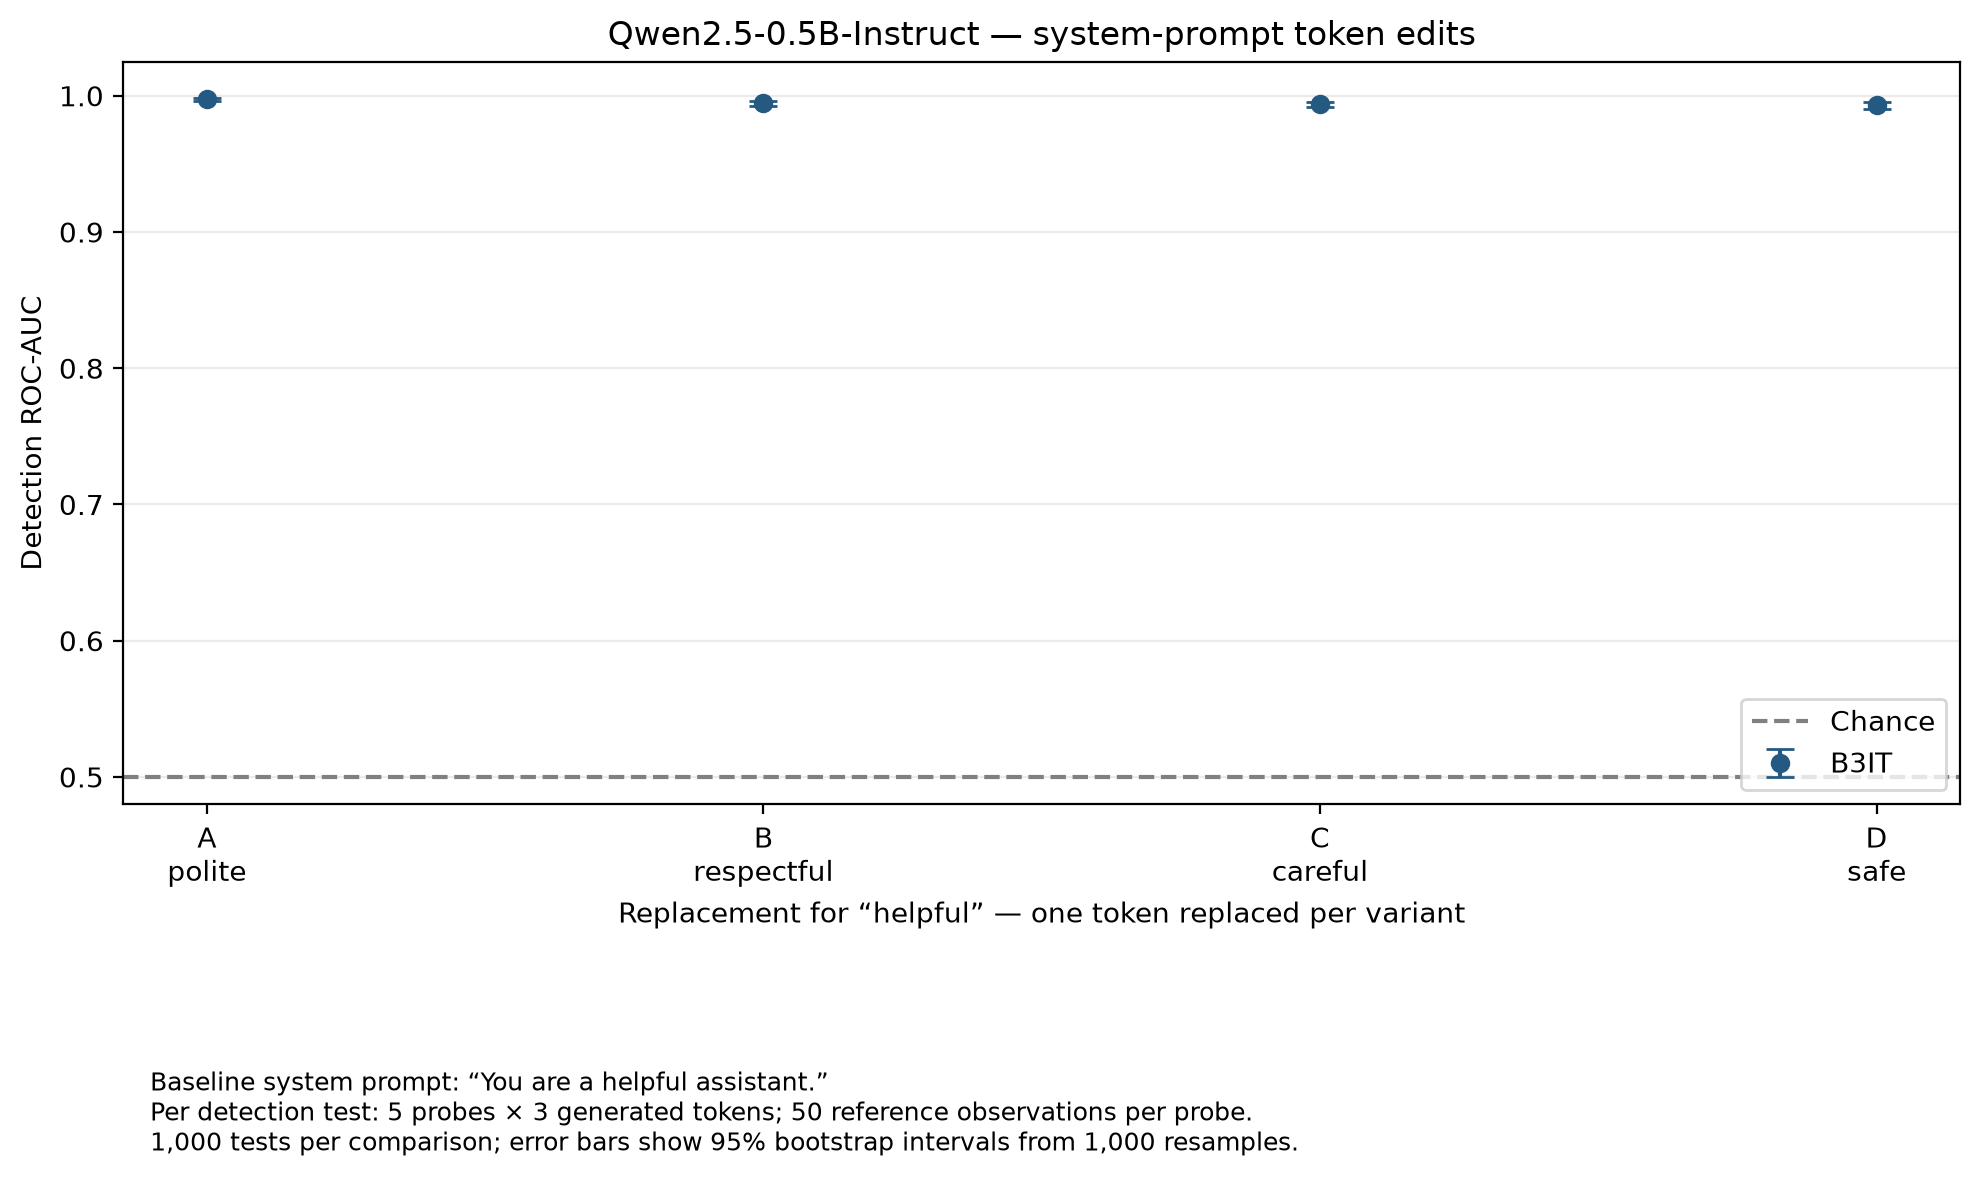

In [17]:
from pathlib import Path
import os
import subprocess
from IPython.display import Image, display

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/plot_b3it.py"

script.write_text(r'''
import csv
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score


def main():
    root = Path(__file__).resolve().parents[1]
    score_dir = root / "results/detection/merged/analysis/bi"
    out = root / "results/scoring"
    figures = root / "results/figures"
    figures.mkdir(exist_ok=True)

    rng = np.random.default_rng(2026)
    n_bootstraps = 1000
    results = {}
    bootstrap_values = {}

    for path in sorted(score_dir.glob("*.json")):
        record = json.loads(path.read_text())
        if record["params"] != {"n_prompts": 5, "detection_samples": 3}:
            continue

        variant = json.loads(record["variant"])
        label = variant["label"]
        h0 = np.asarray(record["h0_stats"]["stats"])
        h1 = np.asarray(record["h1_stats"]["stats"])
        assert len(h0) == 2000 and len(h1) == 1000
        targets = np.r_[np.zeros(len(h0)), np.ones(len(h1))]

        auc = roc_auc_score(targets, np.r_[h0, h1])
        boot = np.empty(n_bootstraps)

        # Preserve the scorer's two equally sized no-change groups.
        for i in range(n_bootstraps):
            sampled_h0 = np.r_[
                rng.choice(h0[:1000], size=1000, replace=True),
                rng.choice(h0[1000:], size=1000, replace=True),
            ]
            sampled_h1 = rng.choice(h1, size=1000, replace=True)
            boot[i] = roc_auc_score(
                targets, np.r_[sampled_h0, sampled_h1]
            )

        low, high = np.quantile(boot, [0.025, 0.975])
        results[label] = {
            "variant": label,
            "replacement": variant["replacement"],
            "tokens_replaced": 1,
            "roc_auc": float(auc),
            "ci_lower": float(low),
            "ci_upper": float(high),
        }
        bootstrap_values[label] = boot

    assert set(results) == set("ABCD")
    rows = [results[label] for label in "ABCD"]

    with (out / "b3it_auc_with_ci.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

    np.savez_compressed(
        out / "b3it_bootstrap_values.npz", **bootstrap_values
    )
    (out / "bootstrap_settings.json").write_text(json.dumps({
        "replicates": n_bootstraps,
        "seed": 2026,
        "interval": "95% percentile",
        "resampling": "within each saved H0 group and H1",
        "scope": "conditional on collected observations and selected probes",
    }, indent=2))

    x = np.arange(4)
    aucs = np.array([r["roc_auc"] for r in rows])
    lower = np.array([r["ci_lower"] for r in rows])
    upper = np.array([r["ci_upper"] for r in rows])

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.errorbar(
        x, aucs,
        yerr=np.vstack([
            np.maximum(aucs - lower, 0),
            np.maximum(upper - aucs, 0),
        ]),
        fmt="o", capsize=5, color="#245a81",
        label="B3IT",
    )
    ax.axhline(0.5, color="gray", linestyle="--", label="Chance")
    ax.set_xticks(x, [f'{r["variant"]}\n{r["replacement"]}' for r in rows])
    ax.set_ylim(0.48, 1.025)
    ax.set_xlabel('Replacement for “helpful” — one token replaced per variant')
    ax.set_ylabel("Detection ROC-AUC")
    ax.set_title("Qwen2.5-0.5B-Instruct — system-prompt token edits")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower right")

    caption = (
        "Baseline system prompt: “You are a helpful assistant.”\n"
        "Per detection test: 5 probes × 3 generated tokens; "
        "50 reference observations per probe.\n"
        "1,000 tests per comparison; error bars show 95% bootstrap intervals "
        "from 1,000 resamples."
    )
    fig.text(0.08, 0.025, caption, fontsize=9, va="bottom")
    fig.tight_layout(rect=(0, 0.19, 1, 1))

    for extension in ("png", "pdf"):
        fig.savefig(
            figures / f"b3it_token_edits.{extension}",
            dpi=200, bbox_inches="tight",
        )
    plt.close(fig)

    for row in rows:
        print(
            f'{row["variant"]}: {row["replacement"]} | '
            f'AUC {row["roc_auc"]:.8f} | '
            f'95% interval [{row["ci_lower"]:.8f}, {row["ci_upper"]:.8f}]'
        )

    print("Figures:", figures)
    print("STEP 16 COMPLETE")


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"

result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), str(script)],
    cwd=ROOT, env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step16_plot.log").write_text(output)

if result.returncode:
    raise RuntimeError("Plotting failed. Send the output above.")

display(Image(filename=str(ROOT / "results/figures/b3it_token_edits.png")))

In [1]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
PYTHON = ROOT / ".venv/bin/python"

for path in (
    PYTHON,
    ROOT / "configs/experiment.json",
    ROOT / "results/scoring/b3it_auc.csv",
    ROOT / "repo/track-llm-apis/src/track_llm_apis/sampling/vllm_sampling.py",
):
    assert path.is_file(), f"Missing: {path}"

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"

check = """
import torch
import transformers
import vllm

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("vLLM:", vllm.__version__)
assert torch.cuda.is_available(), "CUDA unavailable"
print("GPU:", torch.cuda.get_device_name(0))
assert torch.cuda.is_bf16_supported(), "BF16 unavailable"
x = torch.ones((32, 32), device="cuda", dtype=torch.bfloat16)
y = x @ x
torch.cuda.synchronize()
assert y[0, 0].item() == 32
print("BF16 calculation passed")
print("RESUME CHECK COMPLETE")
"""

result = subprocess.run(
    [str(PYTHON), "-c", check],
    cwd=ROOT, env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/lt_resume_hardware.log").write_text(output)

if result.returncode:
    raise RuntimeError("Resume check failed. Send the output above.")

PyTorch: 2.9.1+cu128
Transformers: 4.57.6
vLLM: 0.15.0
GPU: NVIDIA A40
BF16 calculation passed
RESUME CHECK COMPLETE



Step 17 — Prepare LT in the same notebook

In [2]:
from pathlib import Path
import ast
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
SOURCE = ROOT / "repo/track-llm-apis/src/track_llm_apis/sampling"
BACKUP = ROOT / "backups"
BACKUP.mkdir(exist_ok=True)

# Add the system prompt to LT probes and background traffic.
path = SOURCE / "vllm_sampling.py"
text = path.read_text()

old_signature = """    compressed_output: CompressedOutput,
):
"""
new_signature = """    compressed_output: CompressedOutput,
    system_prompt: str | None = None,
):
"""

old_generation = """        outputs = llm.generate(
            batch_prompts, sampling_params, use_tqdm=config.sampling.vllm_use_tqdm
        )"""

new_generation = """        generation_prompts = batch_prompts
        if system_prompt is not None:
            tokenizer = llm.get_tokenizer()
            generation_prompts = [
                {
                    "prompt_token_ids": tokenizer.apply_chat_template(
                        [
                            {"role": "system", "content": system_prompt},
                            {"role": "user", "content": text},
                        ],
                        tokenize=True,
                        add_generation_prompt=True,
                    )
                }
                for text in batch_prompts
            ]

        outputs = llm.generate(
            generation_prompts, sampling_params,
            use_tqdm=config.sampling.vllm_use_tqdm
        )
        # Restore input labels for grouping. Token IDs and logprobs are retained.
        if system_prompt is not None:
            for output, original_prompt in zip(outputs, batch_prompts):
                output.prompt = original_prompt"""

start = text.index("def vllm_inference_random_traffic(")
end = text.index("\ndef vllm_inference(", start)
function = text[start:end]

if new_generation not in function:
    assert function.count(old_signature) == 1
    assert function.count(old_generation) == 1
    updated_function = function.replace(old_signature, new_signature)
    updated_function = updated_function.replace(old_generation, new_generation)
    updated = text[:start] + updated_function + text[end:]
    ast.parse(updated)

    backup = BACKUP / "vllm_sampling.before_lt.py"
    if not backup.exists():
        backup.write_text(text)
    path.write_text(updated)

print("Updated LT sampler:", path)

# ResponseData belongs to an unavailable legacy module.
# It is used only as a type annotation in this file.
path = SOURCE / "analyze_logprobs.py"
text = path.read_text()
old_import = "from track_llm_apis.analyze import ResponseData"

if old_import in text:
    updated = text.replace(
        old_import,
        "from typing import TYPE_CHECKING\n\n"
        "if TYPE_CHECKING:\n"
        "    from track_llm_apis.analyze import ResponseData"
    )
    if not updated.startswith("from __future__ import annotations"):
        updated = "from __future__ import annotations\n\n" + updated
    ast.parse(updated)

    backup = BACKUP / "analyze_logprobs.original.py"
    if not backup.exists():
        backup.write_text(text)
    path.write_text(updated)

print("Updated LT import:", path)

check = r'''
import inspect
import json
from track_llm_apis.config import config
from track_llm_apis.sampling.vllm_sampling import vllm_inference_random_traffic
from track_llm_apis.sampling.analyze_logprobs import (
    logprob_two_sample_test_from_compressed_output_row,
)

assert "system_prompt" in inspect.signature(
    vllm_inference_random_traffic
).parameters

print("\nRepository LT settings:")
print(json.dumps(config.sampling.logprob.model_dump(mode="json"), indent=2))
print("LT sampler and scoring imports passed.")
print("STEP 17 COMPLETE")
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), "-c", check],
    cwd=ROOT, env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step17_lt_setup.log").write_text(output)

if result.returncode:
    raise RuntimeError("LT setup failed. Send the output above.")

Updated LT sampler: /workspace/B3IT_Token_Edits_Fresh/repo/track-llm-apis/src/track_llm_apis/sampling/vllm_sampling.py
Updated LT import: /workspace/B3IT_Token_Edits_Fresh/repo/track-llm-apis/src/track_llm_apis/sampling/analyze_logprobs.py

Repository LT settings:
2026-11-16 13:01:44,196 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-16 13:01:44,197 - track-llm-apis - INFO - No processed dataset found at /data/datasets/lmsys2flmsys-chat-1m, creating...
Traceback (most recent call last):
  File "<string>", line 15, in <module>
  File "/workspace/B3IT_Token_Edits_Fresh/.venv/lib/python3.11/site-packages/pydantic/main.py", line 520, in model_dump
    return self.__pydantic_serializer__.to_python(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<@beartype(track_llm_apis.config.LogprobConfig.other_prompts_dataset_info) at 0x7ccd4692b2e0>", line 12, in other_prompts_dataset_info
  File "/workspace/B3IT_Token_Edits_Fresh/repo/track-llm-apis/src/track_l

RuntimeError: LT setup failed. Send the output above.

In [3]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")

code = r'''
import inspect
import json
from pathlib import Path
from track_llm_apis.config import config

root = Path("/workspace/B3IT_Token_Edits_Fresh")
config.data_dir = root / "data"

from track_llm_apis.sampling.vllm_sampling import vllm_inference_random_traffic
from track_llm_apis.sampling.analyze_logprobs import (
    logprob_two_sample_test_from_compressed_output_row,
)
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts

assert "system_prompt" in inspect.signature(
    vllm_inference_random_traffic
).parameters

# Read declared fields without triggering computed dataset properties.
lt = config.sampling.logprob
settings = {
    name: getattr(lt, name)
    for name in type(lt).model_fields
}
print("Repository LT settings:")
print(json.dumps(settings, indent=2, default=str))

traffic = _load_traffic_prompts()
assert len(traffic) > 0
print("Saved background requests:", len(traffic))
print("Dataset directory:", config.datasets_dir)

(root / "configs/lt_repository_settings.json").write_text(
    json.dumps(settings, indent=2, default=str)
)
print("LT sampler and scoring imports passed.")
print("STEP 17 COMPLETE")
'''

result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), "-c", code],
    cwd=ROOT, env=env, capture_output=True, text=True
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step17_lt_verification.log").write_text(output)

if result.returncode:
    raise RuntimeError("Verification failed. Send the output above.")

Repository LT settings:
{
  "batch_size": 64,
  "topk": 20,
  "temperature": 0.0,
  "reference_samples_per_prompt": 50,
  "default_prompt": "x"
}
Saved background requests: 4502
Dataset directory: /workspace/B3IT_Token_Edits_Fresh/data/datasets
LT sampler and scoring imports passed.
STEP 17 COMPLETE
2026-11-16 13:20:23,998 - track-llm-apis - INFO - Loading the lmsys/lmsys-chat-1m dataset...
2026-11-16 13:20:24,000 - track-llm-apis - INFO - Already processed dataset found at /workspace/B3IT_Token_Edits_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
2026-11-16 13:20:24,213 - track-llm-apis - INFO - Loaded 4502 traffic prompts



Step 18 — Verify LT sampling and saved log probabilities

In [4]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/lt_verify.py"

script.write_text(r'''
import json
import random
from pathlib import Path

import torch
from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts
from track_llm_apis.sampling.common import CompressedOutput, DataSource
from track_llm_apis.sampling.vllm_sampling import (
    vllm_inference_random_traffic,
    cleanup_vllm,
)
from track_llm_apis.sampling.analyze_logprobs import (
    logprob_two_sample_test_from_compressed_output_row,
)
from track_llm_apis.tinychange import TinyChange


class VerifiedLLM(LLM):
    def generate(self, prompts, *args, **kwargs):
        outputs = super().generate(prompts, *args, **kwargs)
        assert len(outputs) == len(prompts)

        # Verify the actual token IDs used by vLLM.
        for request, output in zip(prompts, outputs):
            assert list(output.prompt_token_ids) == request["prompt_token_ids"]

            if request["prompt_token_ids"] == self.expected_probe_ids:
                completion = output.outputs[0]
                assert len(completion.token_ids) == 1
                assert completion.logprobs is not None
                self.observed_logprobs.append({
                    int(token): value.logprob
                    for token, value in completion.logprobs[0].items()
                })
        return outputs


def main():
    root = Path(__file__).resolve().parents[1]
    plan = json.loads((root / "configs/experiment.json").read_text())
    config.data_dir = root / "data"
    config.analysis.device = "cpu"
    config.sampling.vllm_use_tqdm = False
    lt = config.sampling.logprob
    prompt = lt.default_prompt

    llm = VerifiedLLM(
        model=plan["model"],
        revision=plan["model_revision"],
        tokenizer_revision=plan["model_revision"],
        dtype=plan["dtype"],
        enforce_eager=True,
        enable_prefix_caching=False,
        gpu_memory_utilization=0.80,
        seed=0,
    )
    llm.expected_probe_ids = llm.get_tokenizer().apply_chat_template(
        [
            {"role": "system", "content": plan["baseline_system_prompt"]},
            {"role": "user", "content": prompt},
        ],
        tokenize=True,
        add_generation_prompt=True,
    )
    llm.observed_logprobs = []
    data = CompressedOutput(
        model_name=plan["model"],
        gpus=[torch.cuda.get_device_name(0)],
    )

    random.seed(600000)
    vllm_inference_random_traffic(
        llm=llm,
        prompts=[prompt],
        other_prompts=_load_traffic_prompts(),
        batch_size=lt.batch_size,
        n_samples=60,
        max_tokens=1,
        temperature=lt.temperature,
        logprobs_topk=lt.topk,
        variant=TinyChange.unchanged_str(),
        source=DataSource.LT,
        compressed_output=data,
        system_prompt=plan["baseline_system_prompt"],
    )

    assert len(data.rows) == 60
    assert len(llm.observed_logprobs) == 60
    for row, observed in zip(data.rows, llm.observed_logprobs):
        assert row.prompt == (prompt, len(llm.expected_probe_ids))
        assert row.first_token_logprobs == observed
        assert len(observed) >= lt.topk

    out = root / "results/lt/verification"
    data.dump_json(out)
    loaded = CompressedOutput.from_json_dir(out)
    assert len(loaded.rows) == 60
    for row, observed in zip(loaded.rows, llm.observed_logprobs):
        assert row.first_token_logprobs == observed

    score = logprob_two_sample_test_from_compressed_output_row(
        {prompt: loaded.rows[:50]},
        {prompt: loaded.rows[50:]},
        pvalue_b=0,
    )
    report = {
        "gpu": torch.cuda.get_device_name(0),
        "system_prompt": plan["baseline_system_prompt"],
        "prompt": prompt,
        "observations": 60,
        "topk_requested": lt.topk,
        "prompt_token_ids_verified": True,
        "saved_logprobs_match_vllm": True,
        "reload_verified": True,
        "original_vs_original_statistic": score.statistic,
    }
    (out / "verification.json").write_text(json.dumps(report, indent=2))

    print(json.dumps(report, indent=2), flush=True)
    cleanup_vllm(llm)
    print("STEP 18 COMPLETE", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step18_lt_verification.log"
with log_path.open("w") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"LT verification failed. Send the output from {log_path}")

[2026-11-16 13:23:22] INFO font_manager.py:1848: generated new fontManager
INFO 11-16 13:23:50 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-16 13:24:55 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-16 13:24:55 [model.py:1561] Using max model len 32768
INFO 11-16 13:24:57 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-16 13:24:57 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-16 13:24:57 [vllm.py:662] Enforce eager set, overriding optimization level to -O0
INFO 11-16 13:24:57 [vllm.py:762] Cudagraph is disabled under eager mode
WARNING 11-16 13:24:58 [serial_utils.py:57] Allowing insecure serialization using pickle due to VLLM_AL

Step 19 — Collect LT observations for all five conditions

In [5]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/lt_collect.py"

script.write_text(r'''
import gzip
import json
import random
import time
from pathlib import Path

import orjson
import torch
from vllm import LLM
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts
from track_llm_apis.sampling.common import CompressedOutput, DataSource
from track_llm_apis.sampling.vllm_sampling import (
    vllm_inference_random_traffic,
    cleanup_vllm,
)


def main():
    root = Path(__file__).resolve().parents[1]
    plan = json.loads((root / "configs/experiment.json").read_text())
    mapping = json.loads(
        (root / "results/detection/merged/condition_mapping.json").read_text()
    )
    verification = json.loads(
        (root / "results/lt/verification/verification.json").read_text()
    )
    assert verification["saved_logprobs_match_vllm"]
    assert verification["prompt_token_ids_verified"]

    config.data_dir = root / "data"
    config.sampling.vllm_use_tqdm = False
    lt = config.sampling.logprob
    gpu = torch.cuda.get_device_name(0)

    conditions = {"original": plan["baseline_system_prompt"]}
    conditions.update({
        v["label"]: v["system_prompt"] for v in plan["variants"]
    })
    out = root / "results/lt/collection"
    out.mkdir(parents=True, exist_ok=True)

    settings = {
        "model": plan["model"],
        "revision": plan["model_revision"],
        "dtype": plan["dtype"],
        "gpu": gpu,
        "prompt": lt.default_prompt,
        "conditions": conditions,
        "variant_mapping": mapping,
        "observations_per_condition": 5000,
        "block_size": 100,
        "batch_size": lt.batch_size,
        "topk": lt.topk,
        "temperature": lt.temperature,
        "max_output_tokens": 1,
        "reference_samples_per_prompt": lt.reference_samples_per_prompt,
        "seed_base": 700000,
        "prefix_caching": False,
        "enforce_eager": True,
    }
    manifest = out / "settings.json"
    if manifest.exists():
        assert json.loads(manifest.read_text()) == settings, (
            "Saved LT settings or GPU differ from this run."
        )
    else:
        manifest.write_text(json.dumps(settings, indent=2))

    traffic = _load_traffic_prompts()
    llm = None

    for condition, system_prompt in conditions.items():
        folder = out / condition
        folder.mkdir(exist_ok=True)
        started = time.monotonic()
        fresh_observations = 0

        for start in range(0, 5000, 100):
            path = folder / f"block_{start:05d}.json.gz"

            if path.exists():
                with gzip.open(path, "rb") as f:
                    saved = CompressedOutput.from_json(orjson.loads(f.read()))
                assert len(saved.rows) == 100
                assert all(
                    row.variant == mapping[condition]
                    and row.prompt[0] == lt.default_prompt
                    and row.logprobs_idx is not None
                    for row in saved.rows
                )
                print(
                    f"{condition}: verified saved {start + 100}/5000",
                    flush=True,
                )
                continue

            if llm is None:
                llm = LLM(
                    model=plan["model"],
                    revision=plan["model_revision"],
                    tokenizer_revision=plan["model_revision"],
                    dtype=plan["dtype"],
                    enforce_eager=True,
                    enable_prefix_caching=False,
                    gpu_memory_utilization=0.80,
                    seed=0,
                )

            data = CompressedOutput(model_name=plan["model"], gpus=[gpu])
            random.seed(settings["seed_base"] + start)

            vllm_inference_random_traffic(
                llm=llm,
                prompts=[lt.default_prompt],
                other_prompts=traffic,
                batch_size=lt.batch_size,
                n_samples=100,
                max_tokens=1,
                temperature=lt.temperature,
                logprobs_topk=lt.topk,
                variant=mapping[condition],
                source=DataSource.LT,
                compressed_output=data,
                system_prompt=system_prompt,
            )

            expected_ids = llm.get_tokenizer().apply_chat_template(
                [
                    {"role": "system", "content": system_prompt},
                    {"role": "user", "content": lt.default_prompt},
                ],
                tokenize=True,
                add_generation_prompt=True,
            )
            assert len(data.rows) == 100
            for row in data.rows:
                assert row.prompt == (lt.default_prompt, len(expected_ids))
                assert row.variant == mapping[condition]
                assert row.text[1] == 1
                assert len(row.first_token_logprobs) >= lt.topk

            temp = path.with_suffix(".tmp")
            with gzip.open(temp, "wb") as f:
                f.write(orjson.dumps(data.to_json()))
            temp.replace(path)

            fresh_observations += 100
            remaining = (
                (time.monotonic() - started) / fresh_observations
                * (5000 - start - 100) / 60
            )
            print(
                f"{condition}: saved {start + 100}/5000 | "
                f"about {remaining:.1f} min left for this condition",
                flush=True,
            )

    if llm is not None:
        cleanup_vllm(llm)
    print("Saved:", out, flush=True)
    print("STEP 19 COMPLETE | 5 conditions × 5000 LT observations", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
env["HF_HOME"] = str(ROOT / "cache/huggingface")
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step19_lt_collection.log"
print("LT collection log:", log_path, flush=True)

with log_path.open("a") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"LT collection stopped. Send the output from {log_path}")

LT collection log: /workspace/B3IT_Token_Edits_Fresh/logs/step19_lt_collection.log
[2026-11-16 13:48:55] INFO util.py:50: Loading the lmsys/lmsys-chat-1m dataset...
[2026-11-16 13:48:55] INFO util.py:54: Already processed dataset found at /workspace/B3IT_Token_Edits_Fresh/data/datasets/lmsys2flmsys-chat-1m, loading...
[2026-11-16 13:48:55] INFO bi_phase_1.py:189: Loaded 4502 traffic prompts
INFO 11-16 13:48:56 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'tokenizer_revision': '7ae557604adf67be50417f59c2c2f167def9a775', 'enforce_eager': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
INFO 11-16 13:48:56 [model.py:541] Resolved architecture: Qwen2ForCausalLM
INFO 11-16 13:48:56 [model.py:1561] Using max model len 32768
INFO 11-16 13:48:58 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-16 13:48:58 

Step 20 — Verify and score LT

In [6]:
from pathlib import Path
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/score_lt.py"

script.write_text(r'''
import csv
import gzip
import json
import random
from pathlib import Path

import numpy as np
import orjson
import torch
from sklearn.metrics import roc_auc_score

from track_llm_apis.config import config
from track_llm_apis.sampling.common import (
    CompressedOutput, DataSource, SingleVariantResult,
)
from track_llm_apis.sampling.analyze_param_sweeps import LTParameterSweep
from track_llm_apis.tinychange import TinyChange


def main():
    root = Path(__file__).resolve().parents[1]
    config.data_dir = root / "data"
    config.analysis.device = "cpu"
    config.analysis.param_chunk_index = None
    torch.set_num_threads(1)

    collection = root / "results/lt/collection"
    settings = json.loads((collection / "settings.json").read_text())
    mapping = settings["variant_mapping"]
    assert mapping["original"] == TinyChange.unchanged_str()
    assert settings["observations_per_condition"] == 5000
    assert settings["topk"] == 20
    assert settings["prompt"] == config.sampling.logprob.default_prompt

    data = CompressedOutput(
        model_name=settings["model"], gpus=[settings["gpu"]]
    )

    for condition in ("original", "A", "B", "C", "D"):
        count = 0
        for start in range(0, 5000, 100):
            path = collection / condition / f"block_{start:05d}.json.gz"
            with gzip.open(path, "rb") as f:
                block = CompressedOutput.from_json(orjson.loads(f.read()))

            assert len(block.rows) == 100
            assert block.model_name == settings["model"]
            assert block.gpus == [settings["gpu"]]

            for row in block.rows:
                assert row.variant == mapping[condition]
                assert row.source == DataSource.LT.value
                assert row.prompt[0] == settings["prompt"]
                assert row.text[1] == 1
                assert len(row.first_token_logprobs) >= 20

            data.merge(block)
            count += len(block.rows)

        assert count == 5000
        print(f"Verified {condition}: {count} LT observations", flush=True)

    assert len(data.rows) == 25000
    directory = root / "results/lt/merged"
    data.dump_json(directory)

    out = root / "results/lt/scoring"
    out.mkdir(parents=True, exist_ok=True)
    score_settings = {
        "reference_observations": 50,
        "detection_observations": 10,
        "n_tests": 1000,
        "seed": 42,
        "prompt": settings["prompt"],
        "topk": 20,
        "gpu_used_for_collection": settings["gpu"],
        "h0": "original/original and edited/edited, pooled by repository scorer",
        "h1": "original reference versus edited detection",
    }
    (out / "settings.json").write_text(json.dumps(score_settings, indent=2))

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    LTParameterSweep.compute_stats(
        directory=directory,
        data=data,
        n_samples_values=[10],
        reference_samples_per_prompt=50,
        n_tests=1000,
    )

    results = {}
    for path in (directory / "analysis/lt").glob("*.json"):
        result = SingleVariantResult.model_validate_json(path.read_bytes())
        if result.params != {"detection_samples_per_prompt": 10}:
            continue

        metadata = json.loads(result.variant)
        label = metadata["label"]
        assert result.variant == mapping[label]
        assert len(result.h0_stats.stats) == 2000
        assert len(result.h1_stats.stats) == 1000

        h0 = np.asarray(result.h0_stats.stats)
        h1 = np.asarray(result.h1_stats.stats)
        assert np.isfinite(h0).all() and np.isfinite(h1).all()
        auc = roc_auc_score(
            np.r_[np.zeros(len(h0)), np.ones(len(h1))],
            np.r_[h0, h1],
        )
        results[label] = {
            "variant": label,
            "replacement": metadata["replacement"],
            "roc_auc": float(auc),
            "highest_no_change": float(h0.max()),
            "lowest_change": float(h1.min()),
            "every_change_higher": bool(h1.min() > h0.max()),
        }

    assert set(results) == set("ABCD")
    path = out / "lt_auc_sanity_check.csv"
    with path.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(results["A"]))
        writer.writeheader()
        for label in "ABCD":
            row = results[label]
            writer.writerow(row)
            print(
                f'{label} | AUC {row["roc_auc"]:.8f} | '
                f'max H0 {row["highest_no_change"]:.8f} | '
                f'min H1 {row["lowest_change"]:.8f} | '
                f'every change higher: {row["every_change_higher"]}',
                flush=True,
            )

    print("Saved:", path)
    print("Raw scores:", directory / "analysis/lt")
    print("STEP 20 COMPLETE", flush=True)


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
env["PYTHONUNBUFFERED"] = "1"

log_path = ROOT / "logs/step20_lt_scoring.log"
with log_path.open("w") as log:
    with subprocess.Popen(
        [str(ROOT / ".venv/bin/python"), str(script)],
        cwd=ROOT, env=env, stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT, text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        if process.wait():
            raise RuntimeError(f"LT scoring stopped. Send the output from {log_path}")

2026-11-16 14:50:47,691 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,712 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,740 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,767 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,787 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,808 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,830 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,851 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,873 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,899 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,922 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50:47,946 - track-llm-apis - INFO - Loading compressed output v1...
2026-11-16 14:50

Step 21 — Generate the combined B3IT–LT graph

A: polite | B3IT 0.99751725 | LT 1.00000000
B: respectful | B3IT 0.99440625 | LT 1.00000000
C: careful | B3IT 0.99374400 | LT 1.00000000
D: safe | B3IT 0.99298325 | LT 1.00000000
Saved PNG, PDF and CSV: /workspace/B3IT_Token_Edits_Fresh/results/comparison
STEP 21 COMPLETE



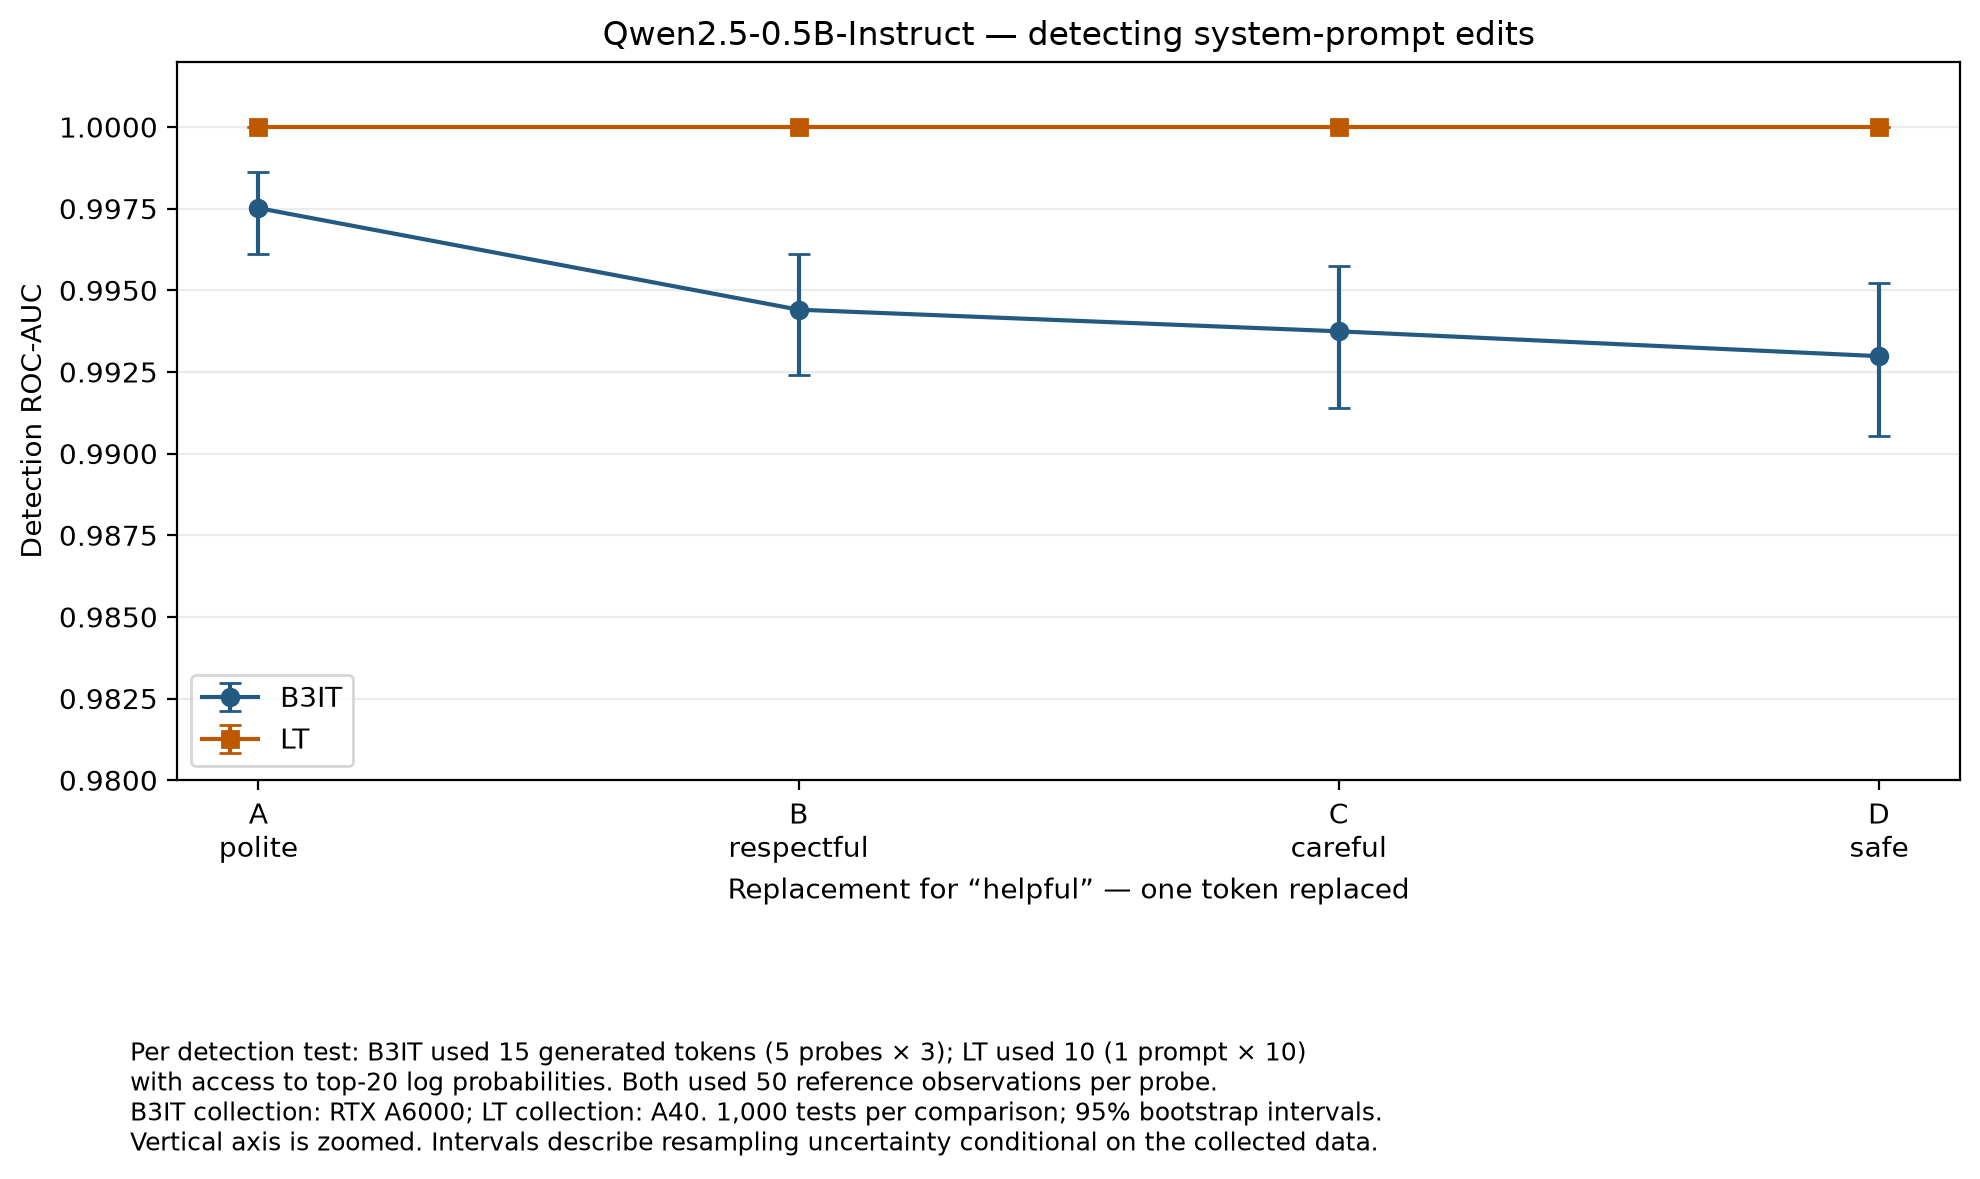

In [7]:
from pathlib import Path
import os
import subprocess
from IPython.display import Image, display

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
script = ROOT / "scripts/plot_comparison.py"

script.write_text(r'''
import csv
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score


def main():
    root = Path(__file__).resolve().parents[1]
    out = root / "results/comparison"
    out.mkdir(exist_ok=True)

    with (root / "results/scoring/b3it_auc_with_ci.csv").open() as f:
        b3it = {r["variant"]: r for r in csv.DictReader(f)}

    rng = np.random.default_rng(2026)
    rows = []
    bootstraps = {}

    for path in sorted(
        (root / "results/lt/merged/analysis/lt").glob("*.json")
    ):
        record = json.loads(path.read_text())
        if record["params"] != {"detection_samples_per_prompt": 10}:
            continue

        metadata = json.loads(record["variant"])
        label = metadata["label"]
        h0 = np.asarray(record["h0_stats"]["stats"])
        h1 = np.asarray(record["h1_stats"]["stats"])
        assert len(h0) == 2000 and len(h1) == 1000

        targets = np.r_[np.zeros(2000), np.ones(1000)]
        auc = roc_auc_score(targets, np.r_[h0, h1])
        values = np.empty(1000)

        for i in range(1000):
            sampled = np.r_[
                rng.choice(h0[:1000], 1000, replace=True),
                rng.choice(h0[1000:], 1000, replace=True),
                rng.choice(h1, 1000, replace=True),
            ]
            values[i] = roc_auc_score(targets, sampled)

        low, high = np.quantile(values, [0.025, 0.975])
        bootstraps[label] = values
        rows.append({
            "variant": label,
            "replacement": metadata["replacement"],
            "b3it_auc": float(b3it[label]["roc_auc"]),
            "b3it_lower": float(b3it[label]["ci_lower"]),
            "b3it_upper": float(b3it[label]["ci_upper"]),
            "lt_auc": float(auc),
            "lt_lower": float(low),
            "lt_upper": float(high),
        })

    rows.sort(key=lambda r: r["variant"])
    assert [r["variant"] for r in rows] == list("ABCD")

    with (out / "b3it_vs_lt.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

    np.savez_compressed(out / "lt_bootstrap_values.npz", **bootstraps)
    (out / "bootstrap_settings.json").write_text(json.dumps({
        "replicates": 1000,
        "seed": 2026,
        "interval": "95% percentile",
        "scope": "resampling saved scores, conditional on collected data",
    }, indent=2))

    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(4)

    for method, color, marker in (
        ("b3it", "#245a81", "o"),
        ("lt", "#bd5700", "s"),
    ):
        y = np.array([r[f"{method}_auc"] for r in rows])
        low = np.array([r[f"{method}_lower"] for r in rows])
        high = np.array([r[f"{method}_upper"] for r in rows])
        ax.errorbar(
            x, y,
            yerr=np.vstack([
                np.maximum(y - low, 0),
                np.maximum(high - y, 0),
            ]),
            fmt=marker + "-",
            color=color, capsize=4,
            label="B3IT" if method == "b3it" else "LT",
        )

    ax.set_xticks(
        x, [f'{r["variant"]}\n{r["replacement"]}' for r in rows]
    )
    ax.set_ylim(0.98, 1.002)
    ax.set_ylabel("Detection ROC-AUC")
    ax.set_xlabel('Replacement for “helpful” — one token replaced')
    ax.set_title("Qwen2.5-0.5B-Instruct — detecting system-prompt edits")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower left")

    caption = (
        "Per detection test: B3IT used 15 generated tokens (5 probes × 3); "
        "LT used 10 (1 prompt × 10)\n"
        "with access to top-20 log probabilities. Both used 50 reference observations per probe.\n"
        "B3IT collection: RTX A6000; LT collection: A40. "
        "1,000 tests per comparison; 95% bootstrap intervals.\n"
        "Vertical axis is zoomed. Intervals describe resampling uncertainty "
        "conditional on the collected data."
    )
    fig.text(0.07, 0.025, caption, fontsize=9, va="bottom")
    fig.tight_layout(rect=(0, 0.21, 1, 1))

    for extension in ("png", "pdf"):
        fig.savefig(
            out / f"b3it_vs_lt.{extension}",
            dpi=200, bbox_inches="tight",
        )
    plt.close(fig)

    for row in rows:
        print(
            f'{row["variant"]}: {row["replacement"]} | '
            f'B3IT {row["b3it_auc"]:.8f} | LT {row["lt_auc"]:.8f}'
        )
    print("Saved PNG, PDF and CSV:", out)
    print("STEP 21 COMPLETE")


if __name__ == "__main__":
    main()
''')

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
result = subprocess.run(
    [str(ROOT / ".venv/bin/python"), str(script)],
    cwd=ROOT, env=env, capture_output=True, text=True,
)
output = result.stdout + result.stderr
print(output)
(ROOT / "logs/step21_comparison.log").write_text(output)

if result.returncode:
    raise RuntimeError("Comparison plotting failed. Send the output above.")

display(Image(filename=str(ROOT / "results/comparison/b3it_vs_lt.png")))

Saved: /workspace/B3IT_Token_Edits_Fresh/results/comparison/b3it_vs_lt_no_errorbars.png
Saved: /workspace/B3IT_Token_Edits_Fresh/results/comparison/b3it_vs_lt_no_errorbars.pdf


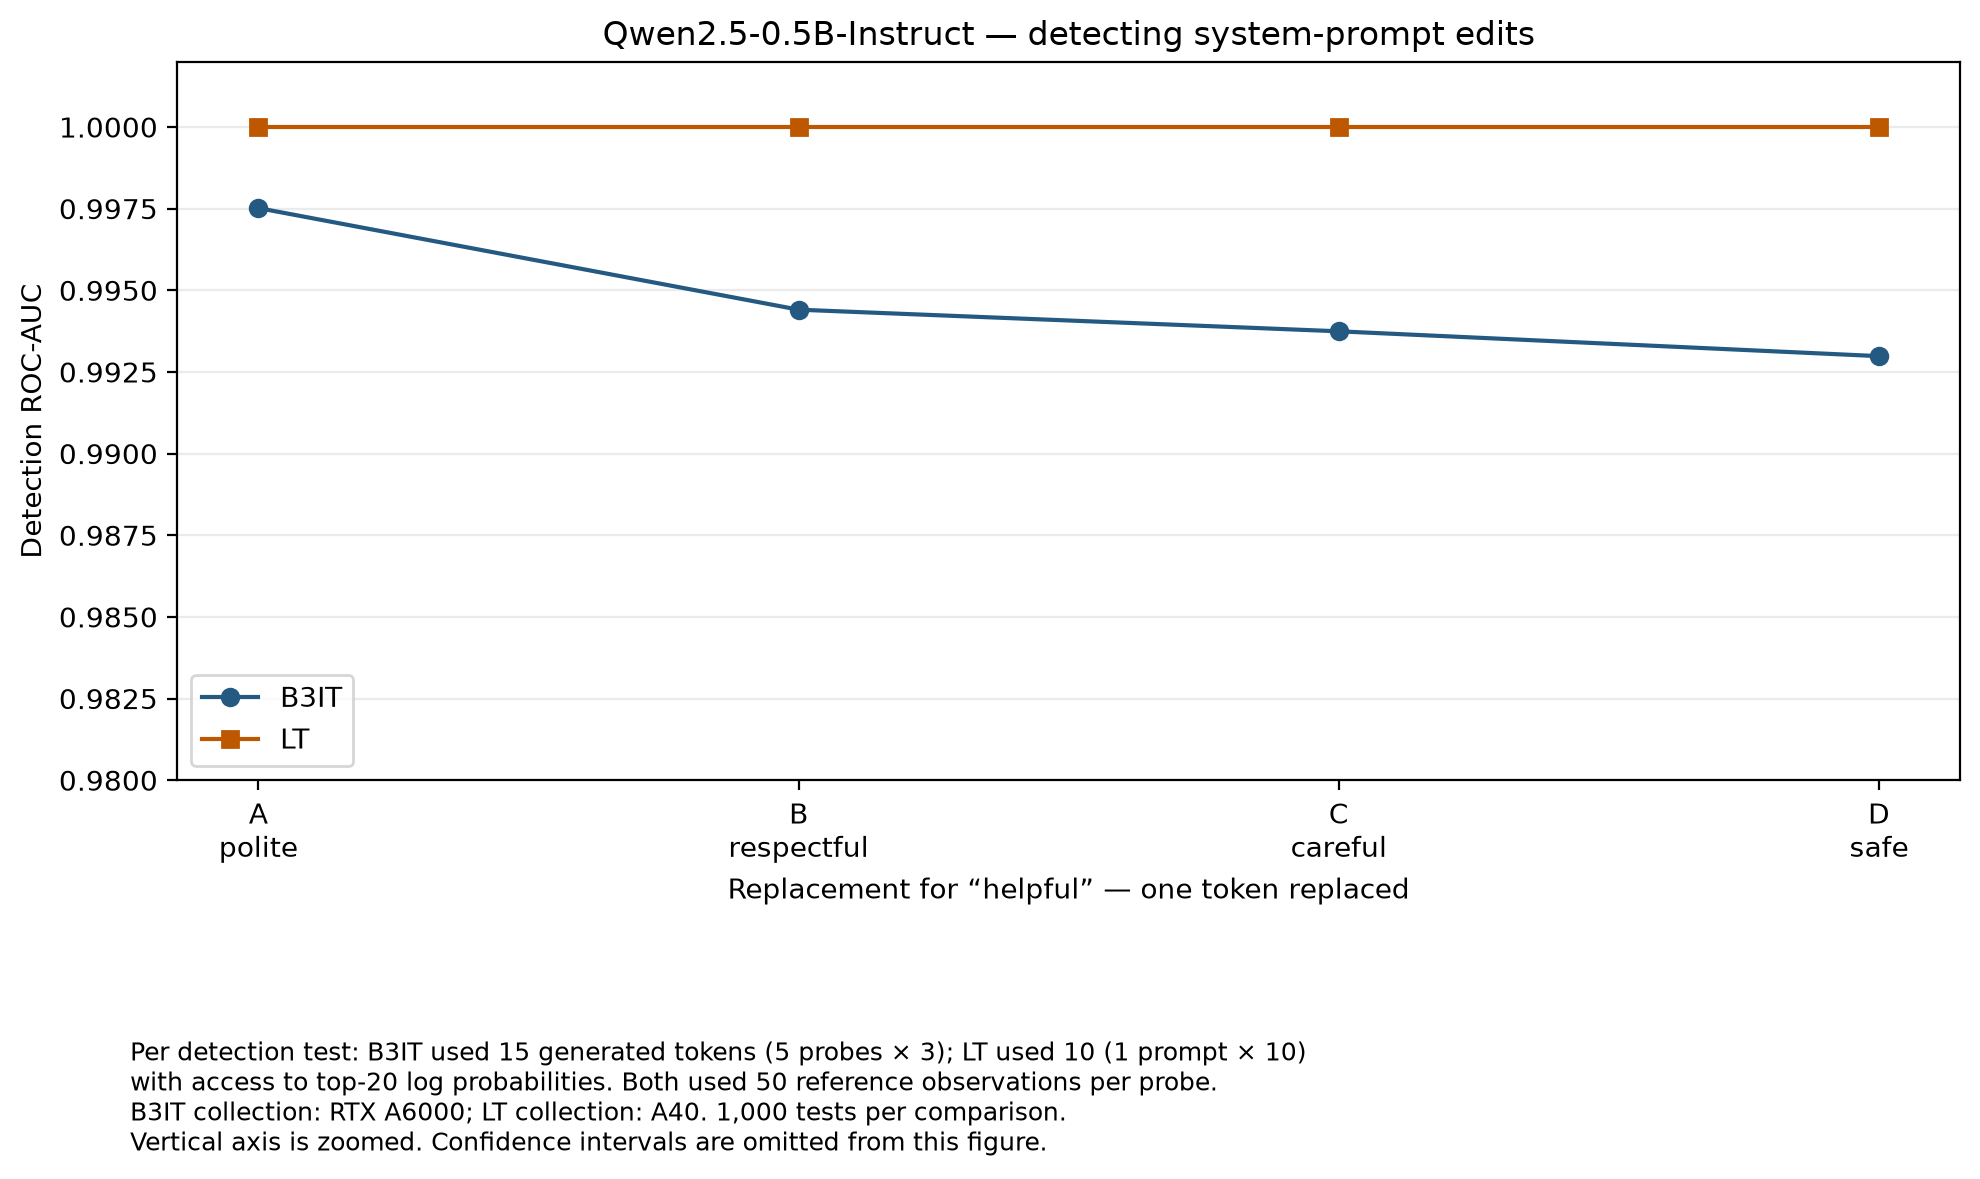

In [1]:
from pathlib import Path
import os
import subprocess
from IPython.display import Image, display

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")

code = r'''
import csv
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

out = Path("/workspace/B3IT_Token_Edits_Fresh/results/comparison")
with (out / "b3it_vs_lt.csv").open() as f:
    rows = sorted(csv.DictReader(f), key=lambda r: r["variant"])

x = range(len(rows))
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(x, [float(r["b3it_auc"]) for r in rows],
        "o-", color="#245a81", label="B3IT")
ax.plot(x, [float(r["lt_auc"]) for r in rows],
        "s-", color="#bd5700", label="LT")

ax.set_xticks(x, [f'{r["variant"]}\n{r["replacement"]}' for r in rows])
ax.set_ylim(0.98, 1.002)
ax.set_ylabel("Detection ROC-AUC")
ax.set_xlabel('Replacement for “helpful” — one token replaced')
ax.set_title("Qwen2.5-0.5B-Instruct — detecting system-prompt edits")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower left")

caption = (
    "Per detection test: B3IT used 15 generated tokens (5 probes × 3); "
    "LT used 10 (1 prompt × 10)\n"
    "with access to top-20 log probabilities. Both used 50 reference observations per probe.\n"
    "B3IT collection: RTX A6000; LT collection: A40. "
    "1,000 tests per comparison.\n"
    "Vertical axis is zoomed. Confidence intervals are omitted from this figure."
)
fig.text(0.07, 0.025, caption, fontsize=9, va="bottom")
fig.tight_layout(rect=(0, 0.21, 1, 1))

for extension in ("png", "pdf"):
    fig.savefig(out / f"b3it_vs_lt_no_errorbars.{extension}",
                dpi=200, bbox_inches="tight")
plt.close(fig)
print("Saved:", out / "b3it_vs_lt_no_errorbars.png")
print("Saved:", out / "b3it_vs_lt_no_errorbars.pdf")
'''

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
subprocess.run(
    [str(ROOT / ".venv/bin/python"), "-c", code],
    env=env, check=True,
)
display(Image(filename=str(
    ROOT / "results/comparison/b3it_vs_lt_no_errorbars.png"
)))

In [2]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display
import hashlib
import json
import os
import subprocess

ROOT = Path("/workspace/B3IT_Token_Edits_Fresh")
assert ROOT.is_dir()

# Choose your saved experiment notebook.
notebooks = sorted(set(
    list(Path("/workspace").glob("*.ipynb"))
    + list(ROOT.glob("*.ipynb"))
    + list((ROOT / "notebooks").glob("*.ipynb"))
))
assert notebooks, "Save your notebook under /workspace, then rerun."

for i, path in enumerate(notebooks, 1):
    print(f"{i}. {path}")

number = int(input("Experiment notebook number: "))
assert 1 <= number <= len(notebooks)
notebook = notebooks[number - 1]

required = [
    "repo/track-llm-apis/src",
    "scripts",
    "configs",
    "data/bi_phase_1",
    "results/detection/probes.json",
    "results/detection/merged",
    "results/scoring",
    "results/lt/collection/settings.json",
    "results/lt/merged",
    "results/lt/scoring",
    "results/comparison",
]

for relative in required:
    assert (ROOT / relative).exists(), f"Missing required item: {relative}"

# Verify that the raw merged observations are present.
for relative in ("results/detection/merged", "results/lt/merged"):
    assert list((ROOT / relative).glob("*.json.gz")), (
        f"Missing merged observations: {relative}"
    )

include = [
    "repo",
    "scripts",
    "configs",
    "data/bi_phase_1",
    "results/discovery_complete.json",
    "results/calibration_blocks/settings.json",
    "results/detection/probes.json",
    "results/detection/merged",
    "results/scoring",
    "results/figures",
    "results/lt/verification",
    "results/lt/collection/settings.json",
    "results/lt/merged",
    "results/lt/scoring",
    "results/comparison",
    "logs/step1_hardware.log",
    "logs/step4_verification.log",
    "logs/lt_resume_hardware.log",
]
include += [
    f"results/detection/{label}/settings.json"
    for label in ("original", "A", "B", "C", "D")
]

skip_dirs = {
    ".git", ".venv", "__pycache__", ".ipynb_checkpoints",
    ".pytest_cache", ".ruff_cache", "node_modules",
    ".cache", "cache", "tools",
}
skip_suffixes = {".pyc", ".safetensors", ".pt", ".pth", ".bin"}
files = {}

for relative in include:
    path = ROOT / relative
    if not path.exists():
        continue

    if path.is_file():
        candidates = [path]
    else:
        candidates = []
        for directory, folders, names in os.walk(path):
            folders[:] = [name for name in folders if name not in skip_dirs]
            candidates.extend(Path(directory) / name for name in names)

    for file in candidates:
        if file.suffix in skip_suffixes:
            continue
        if file.name == ".env" or file.name.startswith(".env."):
            continue
        files[file.relative_to(ROOT).as_posix()] = file

files["notebooks/ExperimentA_Token_Edits.ipynb"] = notebook

# Record the original repository revision using a read-only command.
commit = subprocess.check_output(
    ["git", "-C", str(ROOT / "repo"), "rev-parse", "HEAD"],
    text=True,
).strip()

instructions = """# System-prompt token-edit experiment

Model: Qwen/Qwen2.5-0.5B-Instruct
Baseline: You are a helpful assistant.
Edits: helpful -> polite, respectful, careful, safe.

The merged observations and saved test scores are included.

## Regenerate scores and figures

The current scripts expect this project at:
/workspace/B3IT_Token_Edits_Fresh

Create the environment using the setup cells in the included notebook.
Use the included edited repository and its source files.

Run these saved scripts with the experiment environment's Python:
1. scripts/score_b3it.py
2. scripts/plot_b3it.py
3. scripts/score_lt.py
4. scripts/plot_comparison.py

These steps use the included merged observations.
Fresh GPU sampling is available through the notebook's collection cells.

The no-error-bar figure is generated by the final plotting cell in the notebook.
The included confidence intervals remain available in the saved CSV files.

B3IT used 15 detection output tokens; LT used 10 and top-20 log probabilities.
Both used 50 reference observations per probe.
B3IT observations were collected on RTX A6000; LT observations on A40.

Exact regeneration of saved figures uses the included CSV files.
Rerunning sampling or scoring can vary with hardware and numerical behavior.
"""

archive = Path.cwd() / "B3IT_Token_Edits_Reproducible.zip"
manifest = {}

with ZipFile(archive, "w", ZIP_DEFLATED) as z:
    for name, file in sorted(files.items()):
        z.write(file, name)
        manifest[name] = {
            "bytes": file.stat().st_size,
            "sha256": hashlib.sha256(file.read_bytes()).hexdigest(),
        }

    z.writestr("REPRODUCE.md", instructions)
    z.writestr("upstream_commit.txt", commit + "\n")
    z.writestr("file_manifest.json", json.dumps(manifest, indent=2))

with ZipFile(archive) as z:
    assert z.testzip() is None, "ZIP verification failed."
    print(f"\nVerified {len(z.namelist())} files.")

print(f"ZIP size: {archive.stat().st_size / 1024**2:.1f} MB")
print("Notebook included:", notebook.name)

for name, details in manifest.items():
    if details["bytes"] >= 100 * 1024**2:
        print("Requires Git LFS for GitHub:", name)

display(FileLink(
    archive.name,
    result_html_prefix="Download reproducible experiment ZIP: "
))

1. /workspace/ExperimentA-partB.ipynb


Enter your experiment notebook number:  


ValueError: invalid literal for int() with base 10: ''